# Лабораторная работа № 3

## Контекстный перевод и локализация с помощью LLM (GigaChat / Yandex AI Studio / локальная LLM)

**Студент:** Ключникова Дарья Алексеевна **Группа:** ИНФА-221
**Вариант:** 7 **Предметная область:** Нефтегазовая отрасль: добыча и переработка

**Основная модель:** qwen3.5:9b

**Среда:** Google Colab с GPU T4

## Шаг 0. Структура каталогов: что и куда класть

### Куда класть: одна папка `lab03/input/`

```
/content/                               ← диск Colab (очищается при перезапуске среды)
├── lab03/                              ← создаётся блоком 1
│   ├── input/                          ← ВАШИ ФАЙЛЫ — ТОЛЬКО СЮДА
│   │   ├── variant_25.tmx
│   │   ├── variant_25.tbx
│   │   └── lab02_results.zip           ← целиком, не распаковывая
│   ├── data/                           ← создаётся автоматически, руками не менять
│   │   ├── aligned_reference.csv  glossary.csv  segments_en.csv
│   │   └── lab02/                      ← распакованный архив ЛР № 2 и найденные переводы NMT
│   ├── prompts/                        ← промпты и JSON Schema
│   ├── results/                        ← таблицы и трассировка вызовов
│   ├── figures/                        ← рисунки заданий А–В
│   └── report.md  README.md  prompt_versions.md  requirements.txt  .env.example  .gitignore
└── lab03_results.zip                   ← архив для сдачи (собирает блок 13)
```

## Блок 0. Установка зависимостей

Базовые библиотеки: `pydantic` — проверка структуры ответа, `python-dotenv` — чтение ключей
из `.env` вне Colab, `pandas` и `matplotlib` — таблицы и графики. Библиотека провайдера (`ollama`,
`gigachat` или `yandex-ai-studio-sdk`) ставится в блоке 1 только для выбранного варианта.

In [ ]:
!pip install -q "pydantic>=2" python-dotenv pandas matplotlib

## Блок 1. Параметры эксперимента, каталоги и секреты

**Зачем.** Все решения, от которых зависит результат, собраны в одном месте: провайдер, модель,
температура, зерно, версия промптов, число сегментов, параметры локальной модели и пути к каталогам.
Эти значения попадают в трассировку каждого вызова и в отчёт.

**Что можно менять.**

| Переменная | По умолчанию | Когда менять |
|---|---|---|
| `PROVIDER` | `"ollama"` | облачная модель по ключу: `"gigachat"` или `"yandex"` |
| `MODELS["ollama"]` | `"qwen3.5:9b"` | нет GPU или не хватает памяти: `"qwen3.5:4b"` |
| `MOUNT_DRIVE` | `False` | файлы лежат на Google Drive в `MyDrive/mt_course/` (шаг 0) |

**Параметры локальной модели.** `qwen3.5:9b` — модель с режимом рассуждений, поэтому `OLLAMA_THINK = False`.
В карточке модели штраф за повторы `presence_penalty` равен 1,5; при переводе он подталкивает модель
заменять повторяющиеся слова синонимами, а для терминологии это вредно, поэтому он обнулён.

**Облачные модели.**

| Провайдер | Что нужно | Имена секретов |
|---|---|---|
| Ollama (локально) | GPU T4 в Colab, ключи не нужны | — |
| GigaChat | ключ авторизации из личного кабинета; для физических лиц scope `GIGACHAT_API_PERS` | `GIGACHAT_CREDENTIALS`, `GIGACHAT_SCOPE`, при необходимости `GIGACHAT_CA_BUNDLE` |
| Yandex AI Studio | каталог и API-ключ сервисного аккаунта с ролью `ai.languageModels.user` | `YANDEX_FOLDER_ID`, `YANDEX_API_KEY` |

Секреты добавляются в **Colab Secrets** (значок ключа на левой панели) и читаются функцией
`get_secret()`; их значения нигде не печатаются.

> GigaChat использует сертификаты НУЦ Минцифры. Проверка TLS включена (`verify_ssl_certs=True`). Если
> возникает ошибка доверия, скачайте корневой сертификат, положите его в `/content` и укажите путь к нему
> в секрете `GIGACHAT_CA_BUNDLE`. Отключать проверку не нужно.

In [ ]:
from __future__ import annotations

import difflib
import hashlib
import json
import os
import platform
import re
import shutil
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import pandas as pd

# ------------------------------------------------------------------ параметры эксперимента
PROVIDER = "ollama"          # "ollama" | "gigachat" | "yandex" | "mock" (mock — только проверка кода)
MODELS = {
    "ollama": "qwen3.5:9b",          # Qwen 3.5, 9B, Q4_K_M, ~6.6 ГБ; на T4 работает без ключей
    "gigachat": "GigaChat-2-Max",    # облако Сбера, нужен ключ авторизации
    "yandex": "yandexgpt",           # Yandex AI Studio, нужны folder_id и API-ключ
    "mock": "mock-echo",             # НЕ модель: эхо эталона для проверки пайплайна
}
MODEL = MODELS[PROVIDER]
TEMPERATURE = 0.0            # воспроизводимость важнее разнообразия
SEED = 42
MAX_TOKENS = 800
PROMPT_VERSION = "v1.1"      # v1.1: уточнён стиль B (см. блок 4)

# ------------------------------------------------------------------ локальная модель (Ollama)
OLLAMA_THINK = False             # рассуждения перед ответом выключены: для перевода они не нужны
OLLAMA_NUM_CTX = 8192            # окно контекста: запрос few-shot занимает 1–2 тыс. токенов
OLLAMA_PRESENCE_PENALTY = 0.0    # в карточке модели 1.5; штраф за повторы мешает повторять термины

# ------------------------------------------------------------------ объём эксперимента
N_TEST = 12                  # одинаковые сегменты во всех режимах
FEWSHOT_K = 2                # примеров в few-shot (2–4)
FEWSHOT_STRATEGY = "static"  # "static" — отобранные вручную, "fuzzy" — ближайшие по сходству из ТМ
N_STYLE = 3                  # сегментов для сравнения стилей
N_REPAIR_MIN = 3             # минимум случаев targeted repair
MIN_SEGMENTS = N_TEST + FEWSHOT_K
MIN_TERMS = 10

# ------------------------------------------------------------------ каталоги (см. шаг 0)
MOUNT_DRIVE = True          # True — подключить Google Drive и искать файлы в MyDrive/mt_course
BASE = Path("/content/lab03") if Path("/content").exists() else Path("lab03_work").resolve()
INPUT = BASE / "input"       # ← сюда кладутся файлы ЛР № 1 и ЛР № 2
DATA = BASE / "data"         # создаётся автоматически
RESULTS, PROMPTS, FIGURES = BASE / "results", BASE / "prompts", BASE / "figures"
DRIVE_COURSE_DIR = Path("/content/drive/MyDrive/mt_course")
for folder in (INPUT, DATA, RESULTS, PROMPTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_COURSE_DIR.mkdir(parents=True, exist_ok=True)
        print("Drive подключён:", DRIVE_COURSE_DIR)
    except Exception as error:                      # вне Colab или отказ в доступе
        print("Drive не подключён:", error)

SECRET_NAMES = ["GIGACHAT_CREDENTIALS", "GIGACHAT_SCOPE", "GIGACHAT_CA_BUNDLE",
                "YANDEX_FOLDER_ID", "YANDEX_API_KEY"]


def get_secret(name: str) -> Optional[str]:
    """Секрет из Colab Secrets или переменной окружения. Значение никогда не печатается."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
    return os.environ.get(name)


def pip_install(*packages: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *packages], check=False)


if PROVIDER == "ollama":
    pip_install("ollama>=0.5")       # параметр think появился в ollama-python 0.5
elif PROVIDER == "gigachat":
    pip_install("gigachat")
elif PROVIDER == "yandex":
    pip_install("yandex-ai-studio-sdk")

ENVIRONMENT = {
    "run_date": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "provider": PROVIDER,
    "model": MODEL,
    "temperature": TEMPERATURE,
    "seed": SEED,
    "prompt_version": PROMPT_VERSION,
    "base_dir": str(BASE),
    "input_dir": str(INPUT),
}
if PROVIDER == "ollama":
    ENVIRONMENT.update(think=OLLAMA_THINK, num_ctx=OLLAMA_NUM_CTX,
                       presence_penalty=OLLAMA_PRESENCE_PENALTY)
for key, value in ENVIRONMENT.items():
    print(f"{key:>16}: {value}")
print(f"\nВходные файлы кладите в: {INPUT}")
if PROVIDER == "mock":
    print("\n⚠ PROVIDER = mock: модель НЕ вызывается, результаты — эхо эталона. "
          "Режим нужен только для проверки кода и к сдаче не принимается.")

Mounted at /content/drive
Drive подключён: /content/drive/MyDrive/mt_course
        run_date: 2026-11-19 17:49
          python: 3.13.16
          pandas: 2.2.3
        provider: ollama
           model: qwen3.5:9b
     temperature: 0.0
            seed: 42
  prompt_version: v1.1
        base_dir: /content/lab03
       input_dir: /content/lab03/input
           think: False
         num_ctx: 8192
presence_penalty: 0.0

Входные файлы кладите в: /content/lab03/input


### Блок 1.1. Запуск локальной модели (Ollama)

In [ ]:
# ============================================================================
#  Блок 1.1. Локальная LLM через Ollama (выполняется только при PROVIDER = "ollama")
# ============================================================================
OLLAMA_DIGEST = None


def _run(command: List[str]) -> subprocess.CompletedProcess:
    return subprocess.run(command, capture_output=True, text=True)


def _ollama_alive() -> bool:
    return shutil.which("ollama") is not None and _run(["ollama", "list"]).returncode == 0


def _install_ollama() -> None:
    subprocess.run("apt-get -qq install -y zstd pciutils > /dev/null 2>&1", shell=True)
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)


def _start_server() -> None:
    if _ollama_alive():
        return
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        if _ollama_alive():
            return
        time.sleep(1)
    raise RuntimeError("Сервер Ollama не запустился за 60 секунд")


if PROVIDER == "ollama":
    try:
        gpu = _run(["nvidia-smi", "--query-gpu=name,memory.total",
                    "--format=csv,noheader"]).stdout.strip()
    except FileNotFoundError:
        gpu = ""
    print("GPU:", gpu or "НЕ ОБНАРУЖЕН — подключите T4 (Среда выполнения → Сменить среду выполнения)")

    if shutil.which("ollama") is None:
        print("Устанавливаю Ollama…")
        _install_ollama()
    _start_server()

    print(f"Загружаю модель {MODEL} (первый раз — несколько минут)…")
    if subprocess.run(["ollama", "pull", MODEL]).returncode != 0:
        print("Загрузка не удалась — вероятно, версия Ollama не знает эту модель. Обновляю Ollama…")
        subprocess.run(["pkill", "-f", "ollama serve"])
        _install_ollama()
        _start_server()
        subprocess.run(["ollama", "pull", MODEL], check=True)

    listing = _run(["ollama", "list"]).stdout
    print(listing)
    for line in listing.splitlines():
        if line.split() and line.split()[0] == MODEL:
            OLLAMA_DIGEST = line.split()[1]           # идентификатор конкретной сборки модели
    version = _run(["ollama", "--version"]).stdout.strip().splitlines()
    print(f"Модель: {MODEL} | digest: {OLLAMA_DIGEST} | {version[-1] if version else ''}")

    from ollama import chat
    started = time.perf_counter()                     # прогрев: веса загружаются в видеопамять
    chat(model=MODEL, messages=[{"role": "user", "content": "Ответь одним словом: да"}],
         think=OLLAMA_THINK, options={"num_predict": 4, "num_ctx": OLLAMA_NUM_CTX})
    warmup = time.perf_counter() - started
    print(f"Прогрев: модель загружена в память за {warmup:.0f} с")
    ENVIRONMENT.update({"model_digest": OLLAMA_DIGEST, "gpu": gpu or "нет",
                        "ollama_version": version[-1] if version else "",
                        "warmup_s": round(warmup, 1)})
else:
    print(f"Ollama не требуется: PROVIDER = {PROVIDER}")

GPU: Tesla T4, 15360 MiB
Устанавливаю Ollama…
Загружаю модель qwen3.5:9b (первый раз — несколько минут)…
NAME          ID              SIZE      MODIFIED               
qwen3.5:9b    56671c2ab938    6.6 GB    Less than a second ago    

Модель: qwen3.5:9b | digest: 56671c2ab938 | ollama version is 0.40.16
Прогрев: модель загружена в память за 169 с


## Блок 2. Мой вариант

In [ ]:
# ============================================================================
#  Блок 2. Вариант и предметная область
# ============================================================================
VARIANT = 7
VARIANT_DOMAIN = "Нефтегазовая отрасль: добыча и переработка"
ASK_UPLOAD_IF_MISSING = True # нет файлов ЛР № 1 — блок 2.0 откроет окно загрузки

if VARIANT is None or not VARIANT_DOMAIN:
    print("⚠ Укажите VARIANT и VARIANT_DOMAIN — без них отчёт будет неполным.")
else:
    print(f"Вариант {VARIANT}: {VARIANT_DOMAIN}")

Вариант 7: Нефтегазовая отрасль: добыча и переработка


### Блок 2.0. Поиск входных файлов, разбор TMX/TBX и подключение ЛР № 2

In [ ]:
# ============================================================================
#  Блок 2.0. Поиск входных файлов → input/, разбор TMX/TBX, подключение ЛР № 2
# ============================================================================
import zipfile
import xml.etree.ElementTree as _ET

SERVICE_DIRS = {"sample_data", ".config", "drive", ".ipynb_checkpoints", "__pycache__", ".git"}
OWN_DIRS = {p.resolve() for p in (DATA, RESULTS, PROMPTS, FIGURES)}
NMT_FILES = {"MarianMT": "results_marian.jsonl", "NLLB": "results_nllb.jsonl"}


def _walk(root: Path, max_depth: int):
    """Файлы под root не глубже max_depth уровней, без служебных и выходных папок."""
    root = Path(root)
    if not root.is_dir():
        return
    start = len(root.resolve().parts)
    for dirpath, dirnames, filenames in os.walk(root):
        here = Path(dirpath).resolve()
        if len(here.parts) - start >= max_depth:
            dirnames[:] = []
        else:
            dirnames[:] = [d for d in dirnames
                           if d not in SERVICE_DIRS and (here / d).resolve() not in OWN_DIRS]
        for name in filenames:
            yield here / name


def _search_roots() -> List[Tuple[Path, int]]:
    roots = [(INPUT, 3), (BASE.parent, 4)]
    if DRIVE_COURSE_DIR.is_dir():
        roots.append((DRIVE_COURSE_DIR, 4))
    if Path.cwd().resolve() not in {root.resolve() for root, _ in roots}:
        roots.append((Path.cwd(), 3))
    return roots


def _is_lab02_zip(path: Path) -> bool:
    """Архив ЛР № 2: в названии есть lab02 или внутри лежат results_*.jsonl."""
    if path.suffix.lower() != ".zip" or path.name.startswith("lab03_results"):
        return False
    try:
        with zipfile.ZipFile(path) as archive:
            names = archive.namelist()
    except (zipfile.BadZipFile, OSError):
        return False
    return "lab02" in path.name.lower() or any(n.endswith(tuple(NMT_FILES.values())) for n in names)


def scan_inputs() -> Dict[str, List[Path]]:
    found = {"tmx": [], "tbx": [], "zip": [], "MarianMT": [], "NLLB": [], "lab02_data_dirs": []}
    seen = set()
    for root, depth in _search_roots():
        for path in _walk(root, depth):
            if path in seen:
                continue
            seen.add(path)
            name = path.name.lower()
            if name.endswith(".tmx"):
                found["tmx"].append(path)
            elif name.endswith(".tbx"):
                found["tbx"].append(path)
            elif _is_lab02_zip(path):
                found["zip"].append(path)
            for system, file_name in NMT_FILES.items():
                if name == file_name:
                    found[system].append(path)
            if name in {"source_en.md", "reference_ru.md"} and path.parent not in found["lab02_data_dirs"]:
                found["lab02_data_dirs"].append(path.parent)
    return found


def _in_input(path: Path) -> bool:
    return INPUT.resolve() in path.resolve().parents


def _pick_variant_file(candidates: List[Path], kind: str) -> Optional[Path]:
    """Выбрать один файл: свой вариант, сначала из input/; разные файлы без VARIANT — ошибка."""
    if not candidates:
        return None
    if VARIANT:
        own = [p for p in candidates if re.fullmatch(rf"variant_0*{VARIANT}", p.stem, re.I)]
        if own:
            candidates = own
        else:
            print(f"⚠ Нет файла variant_{VARIANT}.{kind.lower()}; найдены: "
                  + ", ".join(p.name for p in candidates))
    candidates = sorted(candidates, key=lambda p: (not _in_input(p), len(str(p))))
    unique = {}
    for path in candidates:
        unique.setdefault(hashlib.md5(path.read_bytes()).hexdigest(), path)
    if len(unique) > 1:
        listing = "\n  ".join(str(p) for p in unique.values())
        raise RuntimeError(f"Найдено несколько разных файлов {kind}:\n  {listing}\n"
                           f"Оставьте в {INPUT} только файл своего варианта или задайте VARIANT в блоке 2.")
    return candidates[0]


def _to_input(path: Path) -> Path:
    if _in_input(path):
        return path
    target = INPUT / path.name
    shutil.copy2(path, target)
    return target


def _upload_dialog() -> bool:
    try:
        from google.colab import files
    except ImportError:
        return False
    print("Файлы ЛР № 1 не найдены. Выберите variant_<N>.tmx, variant_<N>.tbx "
          "и (желательно) lab02_results.zip:")
    for name, content in files.upload().items():
        (INPUT / name).write_bytes(content)
        print("  сохранён:", INPUT / name)
    return True


def prepare_lab02(found: Dict[str, List[Path]]) -> Dict[str, Dict[str, Any]]:
    """Распаковать архив ЛР № 2 заново и выбрать results_*.jsonl.

    Приоритет: jsonl в input/ → архив в input/ → jsonl в других папках → архив в других папках.
    """
    lab2_dir = DATA / "lab02"
    shutil.rmtree(lab2_dir, ignore_errors=True)        # старая распаковка не мешает новой
    unzipped = lab2_dir / "unzipped"
    unzipped.mkdir(parents=True)
    chosen: Dict[str, Dict[str, Any]] = {}

    def take_loose(paths: List[Path], system: str) -> None:
        if system not in chosen and paths:
            chosen[system] = {"path": paths[0], "origin": str(paths[0])}

    def take_zip(zip_path: Path) -> None:
        target = unzipped / zip_path.stem
        if not target.exists():
            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(target)
            for inner in list(target.rglob("*.zip")):          # вложенный архив
                try:
                    with zipfile.ZipFile(inner) as archive:
                        archive.extractall(inner.with_suffix(""))
                except zipfile.BadZipFile:
                    pass
        for system, file_name in NMT_FILES.items():
            hits = sorted(target.rglob(file_name), key=lambda p: len(p.parts))
            if system not in chosen and hits:
                chosen[system] = {"path": hits[0], "origin": f"{zip_path} → {hits[0].relative_to(target)}"}

    zips_in = [p for p in found["zip"] if _in_input(p)]
    zips_out = [p for p in found["zip"] if not _in_input(p)]
    for system in NMT_FILES:
        take_loose([p for p in found[system] if _in_input(p)], system)
    for zip_path in zips_in:
        take_zip(zip_path)
    for system in NMT_FILES:
        take_loose([p for p in found[system] if not _in_input(p)], system)
    for zip_path in zips_out:
        if len(chosen) < len(NMT_FILES):
            take_zip(zip_path)

    for system, info in chosen.items():
        canonical = lab2_dir / NMT_FILES[system]
        shutil.copy2(info["path"], canonical)
        info["path"] = canonical
    qa_hits = sorted(unzipped.rglob("glossary_qa.csv"), key=lambda p: len(p.parts))
    if qa_hits:
        shutil.copy2(qa_hits[0], lab2_dir / "glossary_qa.csv")
    return chosen


# --- разбор TMX и TBX (тот же адаптер, что в ЛР № 2) ------------------------------
try:                                    # lxml безопаснее: не загружает внешние сущности и DTD
    from lxml import etree as _LET

    def _parse_xml(path):
        parser = _LET.XMLParser(resolve_entities=False, load_dtd=False, no_network=True)
        return _LET.parse(str(path), parser)
except ImportError:                     # pragma: no cover
    def _parse_xml(path):
        return _ET.parse(str(path))

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"


def _lang_of(node) -> str:
    raw = node.get(XML_LANG) or node.get("lang") or ""
    return raw.split("-")[0].lower()


def tmx_to_pairs(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TMX → таблица параллельных сегментов; порядок <tu> задаёт порядок сегментов."""
    rows = []
    for order, tu in enumerate(_parse_xml(path).getroot().iter("tu"), start=1):
        by_lang = {}
        for tuv in tu.findall("tuv"):
            seg = tuv.find("seg")
            text = re.sub(r"\s+", " ", "".join(seg.itertext())).strip() if seg is not None else ""
            if text:
                by_lang[_lang_of(tuv)] = text
        if src_lang in by_lang and tgt_lang in by_lang:
            domain_node = tu.find("prop[@type='domain']")
            rows.append({"segment_id": f"s{order:03d}", "tuid": tu.get("tuid", str(order)),
                         "source": by_lang[src_lang], "reference": by_lang[tgt_lang],
                         "domain": (domain_node.text or "").strip() if domain_node is not None else ""})
    return pd.DataFrame(rows, columns=["segment_id", "tuid", "source", "reference", "domain"])


def tbx_to_glossary(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TBX → таблица терминов en/ru (учитываются <tig><term> и <ntig><termGrp><term>)."""
    rows = []
    for entry in _parse_xml(path).getroot().iter("termEntry"):
        by_lang = {}
        for lang_set in entry.findall("langSet"):
            terms = [t.text.strip() for t in lang_set.iter("term") if (t.text or "").strip()]
            if terms:
                by_lang[_lang_of(lang_set)] = terms[0]
        if src_lang in by_lang and tgt_lang in by_lang:
            rows.append({"en": by_lang[src_lang], "ru": by_lang[tgt_lang], "entry_id": entry.get("id", "")})
    return pd.DataFrame(rows, columns=["en", "ru", "entry_id"])


def load_nmt(path: Optional[Path]) -> Dict[str, str]:
    if path is None:
        return {}
    table = {}
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if line.strip():
            row = json.loads(line)
            key = str(row.get("segment_id") or row.get("id") or "")
            table[key] = row.get("translation") or row.get("hypothesis") or ""
            if row.get("source"):
                NMT_SOURCES.setdefault(path.name, {})[key] = row["source"]
    return table


# --- 1. поиск -----------------------------------------------------------------------
found = scan_inputs()
if not (found["tmx"] and found["tbx"]):
    if globals().get("USE_EMBEDDED_REFERENCE") and "write_reference_set" in globals():
        write_reference_set(INPUT)
        print(f"Файлы ЛР № 1 не найдены — записан встроенный комплект варианта {VARIANT} в {INPUT}")
        found = scan_inputs()
    elif globals().get("ASK_UPLOAD_IF_MISSING", True) and _upload_dialog():
        found = scan_inputs()

TMX_SOURCE = _pick_variant_file(found["tmx"], "TMX")
TBX_SOURCE = _pick_variant_file(found["tbx"], "TBX")
if TMX_SOURCE is None or TBX_SOURCE is None:
    raise FileNotFoundError(
        f"Нет файлов ЛР № 1 (variant_<N>.tmx и variant_<N>.tbx). Положите их в {INPUT} "
        "(см. шаг 0) и перезапустите эту ячейку.")
TMX_PATH, TBX_PATH = _to_input(TMX_SOURCE), _to_input(TBX_SOURCE)
LAB02 = prepare_lab02(found)

# --- 2. разбор TMX/TBX и рабочие таблицы ------------------------------------------------
pairs = tmx_to_pairs(TMX_PATH)
pairs = (pairs[(pairs["source"].str.len() > 0) & (pairs["reference"].str.len() > 0)]
         .drop_duplicates(subset=["source"]).reset_index(drop=True))
pairs["segment_id"] = [f"s{i:03d}" for i in range(1, len(pairs) + 1)]
terms = tbx_to_glossary(TBX_PATH)
terms = (terms[(terms["en"].str.len() > 0) & (terms["ru"].str.len() > 0)]
         .drop_duplicates(subset=["en"]).reset_index(drop=True))
pairs[["segment_id", "source"]].to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
pairs[["segment_id", "source", "reference"]].to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
terms[["en", "ru"]].to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

aligned_df = pairs[["segment_id", "source", "reference"]].copy()
glossary_df = terms[["en", "ru"]].copy()
domains = [d for d in pairs["domain"].fillna("").unique() if d]
DOMAIN_EN = domains[0] if domains else ""
REF_BY_ID = dict(zip(aligned_df["segment_id"], aligned_df["reference"]))
SRC_BY_ID = dict(zip(aligned_df["segment_id"], aligned_df["source"]))

# --- 3. переводы NMT из ЛР № 2 и проверка, что это те же сегменты ----------------------
NMT_SOURCES: Dict[str, Dict[str, str]] = {}
NMT = {system: load_nmt(LAB02.get(system, {}).get("path")) for system in NMT_FILES}
nmt_notes = {}
for system, table in NMT.items():
    if not table:
        continue
    common = set(table) & set(SRC_BY_ID)
    sources = NMT_SOURCES.get(NMT_FILES[system], {})
    mismatched = [sid for sid in common if sources.get(sid) and
                  re.sub(r"\W+", "", sources[sid].lower()) != re.sub(r"\W+", "", SRC_BY_ID[sid].lower())]
    if not common:
        nmt_notes[system] = (f"номера сегментов не совпадают (в файле: {sorted(table)[:3]}…) — "
                             "ЛР № 2 выполнена на другом корпусе")
        NMT[system] = {}
    elif mismatched:
        nmt_notes[system] = (f"исходные тексты не совпадают в {len(mismatched)} сегментах "
                             "(другой вариант?) — сравнение с NMT отключено")
        NMT[system] = {}
    else:
        nmt_notes[system] = f"{len(common)} сегментов совпадают с TMX"

# --- 4. таблица диагностики --------------------------------------------------------------
def _origin(source: Path, used: Path) -> str:
    return "уже в input/" if source == used else f"скопирован из {source}"


print(f"Папка входных файлов: {INPUT}\n")
print(f"  ✓ TMX (ЛР № 1)       {TMX_PATH.name:<24} {_origin(TMX_SOURCE, TMX_PATH)}")
print(f"  ✓ TBX (ЛР № 1)       {TBX_PATH.name:<24} {_origin(TBX_SOURCE, TBX_PATH)}")
for system, file_name in NMT_FILES.items():
    if NMT[system]:
        print(f"  ✓ {system:<8} (ЛР № 2) {file_name:<24} {LAB02[system]['origin']}; {nmt_notes[system]}")
    elif system in nmt_notes:
        print(f"  ⚠ {system:<8} (ЛР № 2) {file_name:<24} {nmt_notes[system]}")
    else:
        print(f"  ✗ {system:<8} (ЛР № 2) {file_name:<24} не найден")
if not any(NMT.values()):
    data_dirs = found["lab02_data_dirs"]
    print("\nРезультаты ЛР № 2 не подключены — сравнение с NMT будет пропущено, остальная работа выполняется.")
    if data_dirs:
        print(f"  Найдена папка с файлами ЛР № 2 без переводов NMT: {data_dirs[0]}\n"
              "  Это содержимое папки data/ из архива; переводы MarianMT и NLLB лежат в results/.")
    print(f"  Что сделать: положите в {INPUT} архив lab02_results.zip целиком (не распаковывая) "
          "или файлы results_marian.jsonl и results_nllb.jsonl и перезапустите эту ячейку.")

lab2_qa = DATA / "lab02" / "glossary_qa.csv"
if lab2_qa.exists():
    qa2 = pd.read_csv(lab2_qa)
    term_col = next((c for c in ("source_term", "term", "en") if c in qa2.columns), None)
    if term_col:
        print("\nТермины, на которых NMT ошибалась в ЛР № 2 (проверяем в первую очередь):",
              ", ".join(qa2[term_col].astype(str).value_counts().index[:10]))

print(f"\nСегментов: {len(aligned_df)} (минимум {MIN_SEGMENTS}), терминов: {len(glossary_df)} "
      f"(минимум {MIN_TERMS}), домен в TMX: {DOMAIN_EN or '—'}")
if len(aligned_df) < MIN_SEGMENTS or len(glossary_df) < MIN_TERMS:
    print("⚠ Объём меньше минимума ЛР № 3 (12 тестовых сегментов + пул few-shot). "
          "Расширьте корпус в ноутбуке ЛР № 1 и перегенерируйте TMX.")

Папка входных файлов: /content/lab03/input

  ✓ TMX (ЛР № 1)       variant_7.tmx            скопирован из /content/drive/MyDrive/mt_course/lab01/variant_7.tmx
  ✓ TBX (ЛР № 1)       variant_7.tbx            скопирован из /content/drive/MyDrive/mt_course/lab01/variant_7.tbx
  ✓ MarianMT (ЛР № 2) results_marian.jsonl     /content/drive/MyDrive/mt_course/lab02/lab02_results.zip → results/results_marian.jsonl; 120 сегментов совпадают с TMX
  ✓ NLLB     (ЛР № 2) results_nllb.jsonl       /content/drive/MyDrive/mt_course/lab02/lab02_results.zip → results/results_nllb.jsonl; 120 сегментов совпадают с TMX

Термины, на которых NMT ошибалась в ЛР № 2 (проверяем в первую очередь): duct, blowout, bit, borehole, recover, casing head, exploration, christmas tree, water hammer, bubble flow

Сегментов: 120 (минимум 14), терминов: 100 (минимум 10), домен в TMX: Нефтегазовая отрасль: добыча и переработка


Все входные файлы найдены: TMX и TBX варианта 7 скопированы с Google Drive, архив ЛР № 2 распакован, переводы MarianMT и NLLB относятся к тем же 120 сегментам, что и память переводов. Домен в TMX совпадает с указанной предметной областью, объём корпуса подходит для работы. Трудные термины, на которых NMT ошибалась в ЛР № 2 (casing head, christmas tree, water hammer, bubble flow), взяты под наблюдение при проверке переводов LLM.

## Блок 3. Тестовые сегменты и примеры few-shot

**Зачем.** Три режима сравниваются только на **одинаковых** сегментах, а примеры few-shot берутся из
**других** сегментов памяти переводов.

**Что делает код.** Первые 12 сегментов — тестовые, остальные — пул примеров. Ниже печатается пул: для
каждого сегмента — исходный текст, эталон и термины глоссария, которые в нём есть.

In [ ]:
# ============================================================================
#  Блок 3. Тестовые сегменты и пул few-shot без пересечения
# ============================================================================
TEST_IDS = aligned_df["segment_id"].head(N_TEST).tolist()
POOL_IDS = [sid for sid in aligned_df["segment_id"] if sid not in TEST_IDS]
assert not set(TEST_IDS) & set(POOL_IDS), "few-shot пересекается с тестом — утечка данных"
print(f"Тестовых сегментов: {len(TEST_IDS)} ({TEST_IDS[0]}–{TEST_IDS[-1]}), пул few-shot: {len(POOL_IDS)}\n")
for sid in POOL_IDS[:12]:
    in_segment = [en for en in glossary_df["en"] if en.lower() in SRC_BY_ID[sid].lower()]
    print(f"{sid}: {SRC_BY_ID[sid]}\n      → {REF_BY_ID[sid]}\n      термины: {', '.join(in_segment) or '—'}")

Тестовых сегментов: 12 (s001–s012), пул few-shot: 108

s013: The bit is on the bottom of the drillstring, usually as part of a rotational motion.
      → Долото находится в нижней части бурильной колонны и обычно участвует во вращательном движении.
      термины: bit
s014: If reservoir fluids flow into another formation and do not flow to the surface, the result is an underground blowout.
      → Если пластовые флюиды перетекают в другой пласт и не выходят на поверхность, возникает подземный выброс.
      термины: blowout
s015: During the appraisal, delineation wells might be drilled to determine the size of the oil or gas field and how to develop it most efficiently.
      → На этапе оценки месторождения могут бурить оценочные скважины, чтобы определить размеры нефтяного или газового месторождения и наиболее эффективный способ его разработки.
      термины: appraisal, gas field
s016: Drillers are often concerned about aquifers and must take special precautions in the design and execut

### Блок 3.1. Описание, чему учит каждый пример

Выбраны 4 сегмента и для каждого записано, **какой тип переводческого решения** он показывает
модели: многозначность в предметной области, составной термин, ложный друг переводчика, нормативная
формулировка, согласование многословного термина. Пример хорош, если в нём есть трудность, на которой
модель может ошибиться, а не просто словарная пара.

In [ ]:
FEWSHOT_NOTES: Dict[str, str] = {
    "s014": "Многозначность в предметной области: blowout в нефтегазе — «выброс», а не «прорыв» или «взрыв».",
    "s021": "Составной термин: beam pump — «глубинный насос штангового типа»; одно английское сочетание разворачивается в многословный русский термин с родительным падежом.",
    "s020": "Ложный друг переводчика: borehole — «ствол скважины», а не просто «скважина»; термин передаётся точно по глоссарию, даже если более общее слово звучит естественнее.",
    "s022": "Нормативная формулировка: ball valve — «шаровой клапан»; проверка буквального следования глоссарию без синонимов вроде «клапан с шаровым затвором»."
}


def words(text: str) -> set:
    return set(re.findall(r"[a-z]+", text.lower()))


def select_fewshot(source: str, k: int = FEWSHOT_K, strategy: str = FEWSHOT_STRATEGY) -> List[str]:
    """segment_id примеров few-shot — всегда из пула, никогда из теста."""
    if strategy == "fuzzy":                        # ближайшие по сходству, как fuzzy match в ЛР № 1
        scored = sorted(POOL_IDS, key=lambda sid: -len(words(source) & words(SRC_BY_ID[sid]))
                        / max(len(words(source) | words(SRC_BY_ID[sid])), 1))
        return scored[:k]
    curated = [sid for sid in FEWSHOT_NOTES if sid in POOL_IDS]
    return (curated + [sid for sid in POOL_IDS if sid not in curated])[:k]


wrong = [sid for sid in FEWSHOT_NOTES if sid not in POOL_IDS]
if wrong:
    print(f"⚠ {wrong} нет в пуле few-shot (это тестовые или несуществующие сегменты) — они не используются")
chosen = select_fewshot(SRC_BY_ID[TEST_IDS[0]])
assert not set(chosen) & set(TEST_IDS), "пример few-shot взят из теста — утечка данных"
print("Примеры few-shot:")
for sid in chosen:
    print(f"  {sid}: {SRC_BY_ID[sid]}\n        → {REF_BY_ID[sid]}\n"
          f"        ✎ {FEWSHOT_NOTES.get(sid) or '— НЕТ ОПИСАНИЯ (заполните FEWSHOT_NOTES)'}")

Примеры few-shot:
  s014: If reservoir fluids flow into another formation and do not flow to the surface, the result is an underground blowout.
        → Если пластовые флюиды перетекают в другой пласт и не выходят на поверхность, возникает подземный выброс.
        ✎ Многозначность в предметной области: blowout в нефтегазе — «выброс», а не «прорыв» или «взрыв».
  s021: A beam pump lifts oil from the reservoir to the surface using a reciprocating sucker-rod system.
        → Глубинный насос штангового типа поднимает нефть из пласта на поверхность с помощью возвратно-поступательной системы насосных штанг.
        ✎ Составной термин: beam pump — «глубинный насос штангового типа»; одно английское сочетание разворачивается в многословный русский термин с родительным падежом.


## Блок 4. Промпты и терминологический контекст

**Зачем.** Промпт — «техническое задание» модели, и его версионируют так же, как код.

**Что делает код.**

* задаёт системную инструкцию с доменом варианта, короткую zero-shot инструкцию, шаблон repair и два
  стилевых варианта;
* `relevant_terms()` выбирает из глоссария **только термины этого сегмента** (без учёта регистра, по
  границам слов, с формой множественного числа; длинные термины — первыми, чтобы «ground control station»
  не перекрывалось словом «station»);
* `user_payload()` собирает сообщение: идентификатор, термины, исходный текст в разделителях `<<< >>>`;
* сохраняет промпты в `prompts/` и печатает их хэши.

In [ ]:
# ============================================================================
#  Блок 4. Промпты: версии, хэши и терминологический контекст сегмента
# ============================================================================
SYSTEM_TEMPLATE = """Ты — профессиональный локализатор учебных материалов в предметной области «{domain}».

Задача: переводить учебный текст с английского языка на русский для студентов вуза.

Правила:
1. Сохраняй смысл, модальность (must / should / can / may) и логические связи.
2. Термины из блока «Термины» передавай строго указанными русскими эквивалентами,
   согласуя их по падежу и числу.
3. Не переводи и не изменяй фрагменты в `обратных кавычках`, идентификаторы, пути к файлам,
   числа и единицы измерения.
4. Сохраняй Markdown-разметку: **выделение**, списки, заголовки.
5. Не добавляй факты, которых нет в исходнике; не сокращай текст.
6. Многозначные слова переводи в значении, принятом в предметной области.
7. {style}
8. Верни только JSON по заданной схеме: segment_id, translation, used_terms, warnings.
   В warnings укажи сомнительные места; если их нет — пустой список."""

STYLE_DEFAULT = "Пиши в нейтральном академическом стиле учебного пособия."
STYLE_A = "Пиши в академическом нейтральном стиле учебного пособия вуза: безличные и пассивные конструкции."
STYLE_B = ("Пиши как дружелюбный преподаватель, объясняющий первокурснику: обращайся к читателю на «вы», "
           "действия оператора формулируй как шаги, которые выполняет читатель (например, «перед взлётом "
           "вы проверяете…»), без разговорного сленга и без новых фактов.")

ZERO_SYSTEM = ("Переведи текст с английского языка на русский. "
               "Верни только JSON по схеме: segment_id, translation, used_terms, warnings.")

REPAIR_TEMPLATE = """Исправь в переводе ТОЛЬКО перечисленные терминологические несоответствия.
Не переписывай остальные части перевода, не меняй порядок слов без необходимости,
не меняй код, Markdown, числа и факты. Согласуй исправленные термины по падежу и числу.

segment_id: {segment_id}
Исходный текст: {source}
Текущий перевод: {translation}
Нарушения (английский термин → обязательный русский эквивалент):
{violations}

Верни JSON по схеме; в warnings перечисли внесённые изменения."""


def _term_pattern(en: str) -> re.Pattern:
    """Термин без учёта регистра, по границам слов, с окончанием -s/-es (waypoint → waypoints)."""
    return re.compile(r"(?<![\w-])" + re.escape(str(en)) + r"(?:s|es)?(?![\w-])", re.IGNORECASE)


TERM_PATTERNS = {str(row.en): _term_pattern(row.en) for row in glossary_df.itertuples(index=False)}


def relevant_terms(source: str, glossary: pd.DataFrame = None) -> List[Tuple[str, str]]:
    """Термины глоссария, встречающиеся в сегменте (длинные — первыми)."""
    glossary = glossary_df if glossary is None else glossary
    found_terms = [(str(r.en), str(r.ru)) for r in glossary.itertuples(index=False)
                   if (TERM_PATTERNS.get(str(r.en)) or _term_pattern(r.en)).search(source)]
    return sorted(found_terms, key=lambda pair: -len(pair[0]))


def user_payload(segment_id: str, source: str, with_terms: bool) -> str:
    lines = [f"segment_id: {segment_id}"]
    terms_here = relevant_terms(source) if with_terms else []
    if terms_here:
        lines.append("Термины (использовать строго):")
        lines += [f"- {en} = {ru}" for en, ru in terms_here]
    lines += ["Исходный текст:", "<<<", source, ">>>"]
    return "\n".join(lines)


def prompt_hash(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:10]


DOMAIN_FOR_PROMPT = VARIANT_DOMAIN or DOMAIN_EN
SYSTEM_PROMPT = SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_DEFAULT)
PROMPT_REGISTRY = {
    "system_controlled": SYSTEM_PROMPT,
    "system_zero": ZERO_SYSTEM,
    "system_style_A": SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_A),
    "system_style_B": SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_B),
    "repair": REPAIR_TEMPLATE,
}
for name, text in PROMPT_REGISTRY.items():
    (PROMPTS / f"{name}.txt").write_text(text, encoding="utf-8")
(PROMPTS / "prompt_system.txt").write_text(SYSTEM_PROMPT, encoding="utf-8")
(PROMPTS / "prompt_repair.txt").write_text(REPAIR_TEMPLATE, encoding="utf-8")
(PROMPTS / "fewshot.json").write_text(json.dumps(
    [{"segment_id": sid, "source": SRC_BY_ID[sid], "translation": REF_BY_ID[sid],
      "note": FEWSHOT_NOTES.get(sid, "")} for sid in select_fewshot(SRC_BY_ID[TEST_IDS[0]])],
    ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Версия промптов: {PROMPT_VERSION}")
for name, text in PROMPT_REGISTRY.items():
    print(f"  {name:<18} sha256:{prompt_hash(text)}  ({len(text)} символов)")
print("\nПример пользовательского сообщения (controlled):\n")
print(user_payload(TEST_IDS[0], SRC_BY_ID[TEST_IDS[0]], with_terms=True))

Версия промптов: v1.1
  system_controlled  sha256:9b663f83f4  (952 символов)
  system_zero        sha256:f14064df19  (121 символов)
  system_style_A     sha256:5f32947092  (992 символов)
  system_style_B     sha256:b36ee30338  (1143 символов)
  repair             sha256:940406b445  (467 символов)

Пример пользовательского сообщения (controlled):

segment_id: s001
Термины (использовать строго):
- sedimentary rocks = осадочные породы
Исходный текст:
<<<
Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
>>>


## Блок 5. JSON Schema и проверка ответа

**Зачем.** Ответ модели должен разбираться программой без ручной чистки. Схема задаёт поля
`segment_id`, `translation`, `used_terms`, `warnings`; модель Pydantic проверяет их типы; смысловые
правила ловят то, что схема пропускает.

**Три уровня проверки.** Синтаксис JSON → поля и типы (Pydantic) → смысл: совпадает `segment_id`, перевод
не пустой, доля кириллицы не ниже 50 %. Перед разбором снимается обёртка ` ```json … ``` `, которую
облачные модели иногда добавляют, если схема не ограничена на сервере.

**На что смотреть.** Четыре контрольных примера: корректный ответ проходит, остальные отклоняются с
понятной причиной.

In [ ]:
# ============================================================================
#  Блок 5. JSON Schema, модель Pydantic и валидация ответа
# ============================================================================
from pydantic import BaseModel, ValidationError

SCHEMA: Dict[str, Any] = {
    "type": "object",
    "properties": {
        "segment_id": {"type": "string"},
        "translation": {"type": "string"},
        "used_terms": {
            "type": "array",
            "items": {"type": "object",
                      "properties": {"source": {"type": "string"}, "target": {"type": "string"}},
                      "required": ["source", "target"],
                      "additionalProperties": False},
        },
        "warnings": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["segment_id", "translation", "used_terms", "warnings"],
    "additionalProperties": False,
}
(PROMPTS / "translation_schema.json").write_text(json.dumps(SCHEMA, ensure_ascii=False, indent=2),
                                                 encoding="utf-8")


class UsedTerm(BaseModel):
    source: str
    target: str


class TranslationResult(BaseModel):
    """Все четыре поля обязательны — так же, как в JSON Schema (required)."""
    segment_id: str
    translation: str
    used_terms: List[UsedTerm]
    warnings: List[str]


def cyrillic_share(text: str) -> float:
    letters = re.findall(r"[A-Za-zА-Яа-яЁё]", text)
    return sum(1 for ch in letters if re.match(r"[А-Яа-яЁё]", ch)) / max(len(letters), 1)


def _strip_code_fence(raw: str) -> str:
    match = re.match(r"^\s*```(?:json)?\s*(.*?)\s*```\s*$", raw or "", re.S)
    return match.group(1) if match else (raw or "")


def validate_response(raw: str, segment_id: str) -> Tuple[Optional[TranslationResult], List[str]]:
    """Три уровня проверки: синтаксис JSON → схема Pydantic → смысловые правила."""
    try:
        data = json.loads(_strip_code_fence(raw))
    except json.JSONDecodeError as error:
        return None, [f"JSON: {error.msg}"]
    try:
        parsed = TranslationResult.model_validate(data)
    except ValidationError as error:
        return None, [f"схема: {str(error).splitlines()[0]}"]
    problems = []
    if parsed.segment_id != segment_id:
        problems.append(f"segment_id: ожидался {segment_id}, получен {parsed.segment_id}")
    if not parsed.translation.strip():
        problems.append("пустой перевод")
    elif cyrillic_share(parsed.translation) < 0.5:
        problems.append("перевод не на русском языке (доля кириллицы < 50 %)")
    return (parsed if not problems else None), problems


print("Схема сохранена:", PROMPTS / "translation_schema.json")
checks = {
    "корректный ответ": '{"segment_id": "s001", "translation": "Проверка связи.", "used_terms": [], "warnings": []}',
    "нет обязательных полей": '{"segment_id": "s001", "translation": "Проверка связи."}',
    "перевод не на русском": '{"segment_id": "s001", "translation": "La búsqueda.", "used_terms": [], "warnings": []}',
    "обрезанный JSON": '{"segment_id": "s001", "translation": "Провер',
}
for label, raw in checks.items():
    parsed, problems = validate_response(raw, "s001")
    print(f"{label:<24} → {'принят' if parsed else 'отклонён: ' + '; '.join(problems)}")

Схема сохранена: /content/lab03/prompts/translation_schema.json
корректный ответ         → принят
нет обязательных полей   → отклонён: схема: 2 validation errors for TranslationResult
перевод не на русском    → отклонён: перевод не на русском языке (доля кириллицы < 50 %)
обрезанный JSON          → отклонён: JSON: Unterminated string starting at


Все четыре контрольных примера обработаны правильно: корректный ответ принят, а ответ без полей, обрезанный JSON и перевод не на русском отклонены с указанием причины. Проверка гарантирует форму и структуру, но не качество перевода, поэтому смысловые ошибки остаются за экспертом.

## Блок 6. Единый вызов LLM и трассировка

**Зачем.** Код режимов не зависит от провайдера: одна функция `translate()` строит сообщения, вызывает
выбранную модель, проверяет ответ, при ошибке повторяет запрос с указанием проблемы и возвращает запись
трассировки (она попадёт в `results/results_llm.jsonl`).

**Как устроены режимы.** zero — короткая инструкция без терминов; controlled — системная инструкция и
термины сегмента; few-shot — то же плюс примеры в виде пар «запрос → JSON-ответ»: так модель видит не
только перевод, но и точный формат.

In [ ]:
# ============================================================================
#  Блок 6. Единый вызов LLM: Ollama, GigaChat, Yandex AI Studio (+ mock для проверки кода)
# ============================================================================
SERVER_SCHEMA = {"gigachat": True, "yandex": True}   # False — схема проверяется только на клиенте


def _call_ollama(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    from ollama import chat
    request = dict(model=MODEL, messages=messages, format=SCHEMA,
                   options={"temperature": TEMPERATURE, "seed": SEED, "num_predict": MAX_TOKENS,
                            "num_ctx": OLLAMA_NUM_CTX, "presence_penalty": OLLAMA_PRESENCE_PENALTY})
    try:
        response = chat(think=OLLAMA_THINK, **request)
    except Exception as error:                      # модель без режима рассуждений
        if "think" not in str(error).lower():
            raise
        response = chat(**request)
    return response.message.content, {"model_version": OLLAMA_DIGEST}


def _fallback_to_client_schema(provider: str, error: Exception) -> bool:
    text = str(error).lower()
    if SERVER_SCHEMA[provider] and any(key in text for key in ("response_format", "json_schema", "400", "422")):
        SERVER_SCHEMA[provider] = False
        print(f"ℹ {provider}: строгая схема на сервере недоступна для этого ключа — дальше формат "
              "проверяется на клиенте (JSON Schema + Pydantic + повтор).")
        return True
    return False


def _call_gigachat(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    from gigachat import GigaChat
    from gigachat.models import Chat, Messages, MessagesRole
    roles = {"system": MessagesRole.SYSTEM, "user": MessagesRole.USER,
             "assistant": MessagesRole.ASSISTANT}
    base = dict(model=MODEL,
                messages=[Messages(role=roles[m["role"]], content=m["content"]) for m in messages],
                temperature=max(TEMPERATURE, 0.01),     # GigaChat ожидает положительную температуру
                max_tokens=MAX_TOKENS)
    client_kwargs = dict(credentials=get_secret("GIGACHAT_CREDENTIALS"),
                         scope=get_secret("GIGACHAT_SCOPE") or "GIGACHAT_API_PERS",
                         verify_ssl_certs=True)          # проверку TLS не отключаем
    if get_secret("GIGACHAT_CA_BUNDLE"):
        client_kwargs["ca_bundle_file"] = get_secret("GIGACHAT_CA_BUNDLE")
    with GigaChat(**client_kwargs) as client:
        response = None
        if SERVER_SCHEMA["gigachat"]:
            try:
                response = client.chat(Chat(**base, response_format={
                    "type": "json_schema", "schema": SCHEMA, "strict": True}))
            except Exception as error:
                if not _fallback_to_client_schema("gigachat", error):
                    raise
        if response is None:
            response = client.chat(Chat(**base))
    return response.choices[0].message.content, {"model_version": getattr(response, "model", None)}


def _call_yandex(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    try:
        from yandex_ai_studio_sdk import AIStudio as SDK
    except ImportError:                         # прежнее название библиотеки
        from yandex_cloud_ml_sdk import YCloudML as SDK
    sdk = SDK(folder_id=get_secret("YANDEX_FOLDER_ID"), auth=get_secret("YANDEX_API_KEY"))
    model = sdk.models.completions(MODEL, model_version="latest")
    payload = [{"role": m["role"], "text": m["content"]} for m in messages]
    result = None
    if SERVER_SCHEMA["yandex"]:
        try:
            result = model.configure(temperature=TEMPERATURE, max_tokens=MAX_TOKENS,
                                     response_format={"json_schema": SCHEMA}).run(payload)
        except Exception as error:
            if not _fallback_to_client_schema("yandex", error):
                raise
    if result is None:
        result = model.configure(temperature=TEMPERATURE, max_tokens=MAX_TOKENS).run(payload)
    return result[0].text, {"model_version": getattr(result, "model_version", None)}


def _call_mock(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    """НЕ модель. Эхо эталона ЛР № 1 для проверки кода; в zero-режиме «забывает» первый термин."""
    last = messages[-1]["content"]
    sid = re.search(r"segment_id:\s*(\S+)", last).group(1)
    translation = REF_BY_ID.get(sid, "Перевод.")
    if messages[0]["content"] == ZERO_SYSTEM:
        terms_here = relevant_terms(SRC_BY_ID.get(sid, ""))
        if terms_here:
            translation = re.sub(re.escape(terms_here[0][1]), terms_here[0][0], translation,
                                 flags=re.I, count=1)
    return json.dumps({"segment_id": sid, "translation": translation, "used_terms": [],
                       "warnings": ["MOCK: не вывод модели"]}, ensure_ascii=False), {"model_version": "mock"}


CALLERS = {"ollama": _call_ollama, "gigachat": _call_gigachat,
           "yandex": _call_yandex, "mock": _call_mock}


def build_messages(segment_id: str, source: str, mode: str, style: str = None) -> List[Dict[str, str]]:
    """zero — короткая инструкция; controlled — системный промпт + термины;
    fewshot — то же + примеры из пула в виде пар user/assistant."""
    if mode == "zero":
        return [{"role": "system", "content": ZERO_SYSTEM},
                {"role": "user", "content": user_payload(segment_id, source, with_terms=False)}]
    system = PROMPT_REGISTRY.get(f"system_style_{style}", SYSTEM_PROMPT) if style else SYSTEM_PROMPT
    messages = [{"role": "system", "content": system}]
    if mode == "fewshot":
        for sid in select_fewshot(source):
            messages.append({"role": "user", "content": user_payload(sid, SRC_BY_ID[sid], True)})
            messages.append({"role": "assistant", "content": json.dumps(
                {"segment_id": sid, "translation": REF_BY_ID[sid],
                 "used_terms": [{"source": en, "target": ru} for en, ru in relevant_terms(SRC_BY_ID[sid])],
                 "warnings": []}, ensure_ascii=False)})
    messages.append({"role": "user", "content": user_payload(segment_id, source, with_terms=True)})
    return messages


def translate(segment_id: str, source: str, mode: str, style: str = None,
              messages: List[Dict[str, str]] = None, max_attempts: int = 3) -> Dict[str, Any]:
    """Вызов с повтором при невалидном ответе. Возвращает запись трассировки."""
    messages = messages or build_messages(segment_id, source, mode, style)
    record = {"segment_id": segment_id, "provider": PROVIDER, "model": MODEL, "mode": mode,
              "style": style, "temperature": TEMPERATURE, "seed": SEED, "prompt_version": PROMPT_VERSION,
              "prompt_hash": prompt_hash(messages[0]["content"]), "source": source,
              "translation": "", "used_terms": [], "warnings": [], "json_valid": False,
              "attempts": 0, "errors": [], "model_version": None, "latency_s": None}
    for attempt in range(1, max_attempts + 1):
        started = time.perf_counter()
        try:
            raw, meta = CALLERS[PROVIDER](messages)
        except Exception as error:                          # сеть, авторизация, квоты
            record["errors"].append(f"вызов: {type(error).__name__}: {error}"[:300])
            break
        record.update(attempts=attempt, latency_s=round(time.perf_counter() - started, 2),
                      model_version=meta.get("model_version"))
        parsed, problems = validate_response(raw, segment_id)
        if parsed:
            record.update(translation=parsed.translation, json_valid=True,
                          used_terms=[t.model_dump() for t in parsed.used_terms],
                          warnings=parsed.warnings)
            break
        record["errors"].extend(problems)
        messages = messages + [{"role": "user", "content":
                                f"segment_id: {segment_id}\nОтвет не прошёл проверку: " + "; ".join(problems) +
                                ". Верни только JSON строго по схеме."}]
    return record


probe = translate(TEST_IDS[0], SRC_BY_ID[TEST_IDS[0]], "controlled")
print(json.dumps({k: probe[k] for k in ("segment_id", "mode", "translation", "json_valid",
                                         "attempts", "latency_s", "model_version", "errors")},
                 ensure_ascii=False, indent=2))

{
  "segment_id": "s001",
  "mode": "controlled",
  "translation": "Осадочные породы образуются в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.",
  "json_valid": true,
  "attempts": 1,
  "latency_s": 17.35,
  "model_version": "56671c2ab938",
  "errors": []
}


Пробный вызов прошёл с первой попытки: модель вернула валидный JSON, ошибок нет, версия модели совпадает с digest из блока 1.1. Перевод s001 совпадает с эталоном по смыслу, термин «осадочные породы» передан по глоссарию, расхождений, которые требовали бы вмешательства, нет.

## Блок 7. Три режима на одинаковых сегментах

**Зачем.** Основной эксперимент: одни и те же 12 сегментов переводятся тремя способами, все вызовы
записываются в `results/results_llm.jsonl` с полной трассировкой. Это самая долгая ячейка (36 вызовов).

**На что смотреть.** Сводку по режимам: долю валидных JSON-ответов, среднее число попыток, время ответа и
число ответов с предупреждениями (`warnings`). Если валидность ниже 100 %, смотрите поле `errors` в
трассировке — обычно это выход за формат или ответ не на том языке.

In [ ]:
# ============================================================================
#  Блок 7. Три режима на одних и тех же сегментах: zero / controlled / few-shot
# ============================================================================
MODES = ["zero", "controlled", "fewshot"]
records: List[Dict[str, Any]] = []
for mode in MODES:
    for sid in TEST_IDS:
        records.append(translate(sid, SRC_BY_ID[sid], mode))
    print(f"{mode:<11} готово: {sum(r['mode'] == mode for r in records)} сегментов")

with open(RESULTS / "results_llm.jsonl", "w", encoding="utf-8") as handle:
    for record in records:
        handle.write(json.dumps(record, ensure_ascii=False) + "\n")

runs = pd.DataFrame(records)
summary = (runs.groupby("mode", sort=False)
           .agg(segments=("segment_id", "count"), json_valid=("json_valid", "mean"),
                mean_attempts=("attempts", "mean"), mean_latency_s=("latency_s", "mean"),
                with_warnings=("warnings", lambda s: sum(bool(w) for w in s)))
           .reindex(MODES))
summary["json_valid"] = (summary["json_valid"] * 100).round(1)
summary["mean_latency_s"] = summary["mean_latency_s"].round(2)
print("\nСводка по режимам (json_valid — доля валидных ответов, %):")
summary

zero        готово: 12 сегментов
controlled  готово: 12 сегментов
fewshot     готово: 12 сегментов

Сводка по режимам (json_valid — доля валидных ответов, %):


,segments,json_valid,mean_attempts,mean_latency_s,with_warnings
mode,,,,,
zero,12,100.0,1.000000,7.51,2
controlled,12,100.0,1.000000,5.40,0
fewshot,12,100.0,1.166667,4.43,0


Все три режима вернули валидный JSON (100 %) практически с первой попытки. При этом поле warnings пусто у controlled и few-shot, хотя в блоке 8 у них есть подтверждённые нарушения, значит, модель не сообщает о своих ошибках и её самооценке доверять нельзя.

## Блок 8. Терминологический контроль

**Зачем.** Главный вопрос работы — помогает ли управление соблюдать глоссарий. Число нарушений
считается для каждого режима LLM и для MarianMT и NLLB из ЛР № 2 — на одних сегментах и по одной
процедуре.

**Как работает проверка.** Для каждого термина сегмента ищется его русский эквивалент в переводе с учётом
словоизменения: у слов отсекаются окончания («наземную» ↔ «наземная»), короткие слова с беглой гласной
сравниваются по сходству («угол» ↔ «угла»). Прилагательное и существительное одного корня («полётный» ↔
«полёта») не совпадают: для глоссария это разные решения. Проверка грубая, поэтому каждое срабатывание
подтверждается вручную в блоке 8.1.

**На что смотреть.** Долю соблюдения по системам **до** ручной проверки. Ожидаемая картина: zero-shot
близок к NMT, controlled и few-shot заметно выше.

In [ ]:
# ============================================================================
#  Блок 8. Терминологический контроль: все режимы LLM и NMT из ЛР № 2
# ============================================================================
RU_ENDINGS = sorted({"иями", "ями", "ами", "ого", "его", "ому", "ему", "ыми", "ими", "ую", "юю",
                     "ая", "яя", "ое", "ее", "ые", "ие", "ый", "ий", "ой", "ей", "ом", "ем", "ём",
                     "ах", "ях", "ам", "ям", "ов", "ев", "ым", "им", "ых", "их", "ь", "и", "ы",
                     "а", "я", "е", "о", "у", "ю"}, key=len, reverse=True)


def ru_stem(word: str) -> str:
    """Грубая нормализация: отсечение окончания (минимум 3 буквы основы)."""
    word = word.lower().replace("ё", "е").strip(".,;:()«»\"'`*")
    for ending in RU_ENDINGS:
        if len(word) - len(ending) >= 3 and word.endswith(ending):
            return word[: -len(ending)]
    return word


def token_match(first: str, second: str) -> bool:
    """Одинаковые основы или беглая гласная в коротком слове («угол» — «угла»)."""
    first, second = ru_stem(first), ru_stem(second)
    if first == second:
        return True
    return (max(len(first), len(second)) <= 4 and first[:2] == second[:2]
            and difflib.SequenceMatcher(None, first, second).ratio() >= 0.75)


def term_present(term_ru: str, text: str) -> bool:
    tokens = re.findall(r"[\wёЁ-]+", (text or "").lower())
    return all(any(token_match(part, token) for token in tokens)
               for part in re.findall(r"[\wёЁ-]+", term_ru.lower()))


def term_violations(source: str, translation: str) -> List[Dict[str, str]]:
    return [{"source_term": en, "expected": ru} for en, ru in relevant_terms(source)
            if not term_present(ru, translation)]


systems = {mode: {r["segment_id"]: r["translation"] for r in records if r["mode"] == mode}
           for mode in MODES}
for name, table in NMT.items():
    if table:
        systems[name] = {sid: table.get(sid, "") for sid in TEST_IDS}

qa_rows, compliance = [], []
occurrences = sum(len(relevant_terms(SRC_BY_ID[sid])) for sid in TEST_IDS)
for system, table in systems.items():
    violations = 0
    for sid in TEST_IDS:
        for violation in term_violations(SRC_BY_ID[sid], table.get(sid, "")):
            violations += 1
            qa_rows.append({"segment_id": sid, "system": system, **violation,
                            "translation": table.get(sid, ""), "confirmed": "", "comment": ""})
    compliance.append({"system": system, "occurrences": occurrences, "violations_auto": violations,
                       "compliance_auto_%": round(100 * (1 - violations / max(occurrences, 1)), 1)})

terminology_qa = pd.DataFrame(qa_rows, columns=["segment_id", "system", "source_term", "expected",
                                                "translation", "confirmed", "comment"])
compliance_df = pd.DataFrame(compliance)
print(f"Вхождений терминов в тестовые сегменты: {occurrences}; срабатываний проверки: {len(terminology_qa)}")
compliance_df

Вхождений терминов в тестовые сегменты: 13; срабатываний проверки: 31


,system,occurrences,violations_auto,compliance_auto_%
0,zero,13,7,46.2
1,controlled,13,3,76.9
2,fewshot,13,3,76.9
3,MarianMT,13,9,30.8
4,NLLB,13,9,30.8


Передача глоссария в промпте дала заметный прирост: zero-shot 46.2 %, controlled и few-shot по 76.9 %, тогда как MarianMT и NLLB остались на 30.8 %. Но 76.9 % не означают безошибочный перевод, потому что проверка видит только термины глоссария, а слова вне его остаются без контроля и разбираются вручную в блоке 12.

### Блок 8.1. Ручное подтверждение срабатываний

Автоматическая проверка ошибается в обе стороны, поэтому **каждое** срабатывание подтверждается
вручную.

| Решение | Когда ставить | Пример |
|---|---|---|
| `"yes"` | нарушение подтверждено: термин передан не так, как в глоссарии | *airframe* → «кузов самолёта» вместо «планёр» |
| `"no"` | ложное срабатывание: термин передан верно, но проверка его не узнала | редкая падежная форма, перестройка фразы, перевод корректен по смыслу |

В комментарии назовите тип ошибки: **неверный термин**, **описательный перевод**, **калька**,
**транслитерация**, **пропуск**, **ошибка проверки**.

In [ ]:
# ============================================================================
#  Блок 8.1. ✏️ ЗАПОЛНИТЬ: решение по каждому срабатыванию терминологической QA
# ============================================================================
QA_DECISIONS: Dict[Tuple[str, str, str], Tuple[str, str]] = {
    # --- exploration ---
    ("s002", "zero", "exploration"): ("yes", "смысловая ошибка: сужение значения, «сейсморазведка» — подвид геологоразведки, а не весь термин"),
    ("s004", "zero", "exploration"): ("yes", "описательный перевод: «разведка месторождений» вместо термина"),
    ("s002", "controlled", "exploration"): ("yes", "смысловая ошибка: сужение значения, «сейсморазведка» — подвид геологоразведки"),
    ("s002", "fewshot", "exploration"): ("yes", "смысловая ошибка: сужение значения, «сейсморазведка» — подвид геологоразведки"),
    ("s002", "MarianMT", "exploration"): ("yes", "смысловая ошибка: сужение значения, «сейсмическая разведка» — подвид"),
    ("s004", "MarianMT", "exploration"): ("yes", "описательный перевод: «полевые исследования»"),
    ("s002", "NLLB", "exploration"): ("yes", "смысловая ошибка: сужение значения, «сейсмическое исследование» — подвид"),
    ("s004", "NLLB", "exploration"): ("yes", "описательный перевод: «полевые исследования»"),

      # --- pressure ---
    ("s005", "zero", "pressure"): ("no", "ошибка проверки: «давления» — верная форма от «давление»"),
    ("s005", "controlled", "pressure"): ("no", "ошибка проверки: «давления» — верная форма от «давление»"),
    ("s005", "fewshot", "pressure"): ("no", "ошибка проверки: «давления» — верная форма от «давление»"),
    ("s005", "MarianMT", "pressure"): ("no", "ошибка проверки: «давления» — верная форма от «давление»"),
    ("s005", "NLLB", "pressure"): ("no", "ошибка проверки: «давления» — верная форма от «давление»"),

    # --- blowout ---
    ("s006", "zero", "blowout"): ("yes", "смысловая ошибка: «разрыв» вместо «выброс» — искажён смысл"),
    ("s008", "zero", "blowout"): ("yes", "пропуск: blowout не передан"),
    ("s006", "MarianMT", "blowout"): ("yes", "смысловая ошибка: «разрыв» вместо «выброс»"),
    ("s007", "MarianMT", "blowout"): ("yes", "пропуск: blowout не передан"),
    ("s008", "MarianMT", "blowout"): ("yes", "пропуск: blowout не передан"),
    ("s006", "NLLB", "blowout"): ("yes", "смысловая ошибка: «взрыв» вместо «выброс»"),
    ("s007", "NLLB", "blowout"): ("yes", "смысловая ошибка: «взрыв» вместо «выброс»"),
    ("s008", "NLLB", "blowout"): ("yes", "пропуск: blowout не передан"),

    # --- christmas tree ---
    ("s009", "zero", "christmas tree"): ("yes", "смысловая ошибка: буквальный перевод «хвойное дерево» вместо «фонтанное устьевое оборудование»"),
    ("s009", "MarianMT", "christmas tree"): ("yes", "смысловая ошибка: буквальный перевод «рождественская ёлка»"),
    ("s009", "NLLB", "christmas tree"): ("yes", "смысловая ошибка: буквальный перевод «рождественская елка»"),

    # --- recover ---
    ("s011", "zero", "recover"): ("yes", "смысловая ошибка: «добыча» вместо «восполнять»"),
    ("s011", "controlled", "recover"): ("no", "ошибка проверки: «восполнения» — верная форма от «восполнять»"),
    ("s011", "fewshot", "recover"): ("no", "ошибка проверки: «восполнения» — верная форма от «восполнять»"),
    ("s011", "MarianMT", "recover"): ("yes", "смысловая ошибка: «извлечение» вместо «восполнение»"),
    ("s011", "NLLB", "recover"): ("yes", "смысловая ошибка: «извлечение» вместо «восполнение»"),

    # --- casing head ---
    ("s008", "MarianMT", "casing head"): ("yes", "пропуск: casing head не передан — смысловая ошибка"),
    ("s008", "NLLB", "casing head"): ("yes", "пропуск / смысловая ошибка: casing head не передан"),
}


def apply_qa_decisions() -> pd.DataFrame:
    """Перенести решения в terminology_qa и пересчитать соблюдение после ручной проверки."""
    keys = list(zip(terminology_qa["segment_id"], terminology_qa["system"], terminology_qa["source_term"]))
    decisions = [QA_DECISIONS.get(key, ("", "")) for key in keys]
    terminology_qa["confirmed"] = [str(d[0]).strip().lower() for d in decisions]
    terminology_qa["comment"] = [d[1] for d in decisions]
    bad = sorted(set(terminology_qa["confirmed"]) - {"yes", "no", ""})
    if bad:
        print(f"⚠ Недопустимые значения {bad}: используйте только \"yes\" или \"no\"")
    unknown = [key for key in QA_DECISIONS if key not in set(keys)]
    if unknown:
        print(f"ℹ {len(unknown)} решений не относятся к текущим срабатываниям "
              f"(например, {unknown[0]}) — они не используются")
    terminology_qa.to_csv(RESULTS / "terminology_qa.csv", index=False, encoding="utf-8-sig")

    grouped = terminology_qa.groupby("system")["confirmed"]
    table = compliance_df[["system", "occurrences", "violations_auto", "compliance_auto_%"]].copy()
    table["false_positives"] = table["system"].map(grouped.apply(lambda s: (s == "no").sum())).fillna(0).astype(int)
    table["undecided"] = table["system"].map(grouped.apply(lambda s: (s == "").sum())).fillna(0).astype(int)
    table["violations_checked"] = table["violations_auto"] - table["false_positives"]
    table["compliance_checked_%"] = (100 * (1 - table["violations_checked"]
                                            / table["occurrences"].clip(lower=1))).round(1)
    return table


compliance_df = apply_qa_decisions()
undecided = terminology_qa[terminology_qa["confirmed"] == ""]
print(f"Решений: {len(terminology_qa) - len(undecided)} из {len(terminology_qa)}")
if len(undecided):
    print("\nЗаготовка для недостающих решений — скопируйте строки в QA_DECISIONS и заполните:\n")
    for row in undecided.itertuples(index=False):
        print(f'    ("{row.segment_id}", "{row.system}", "{row.source_term}"): ("", ""),'
              f'  # «{row.translation[:60]}» | нужно: {row.expected}')
compliance_df

Решений: 31 из 31


,system,occurrences,violations_auto,compliance_auto_%,false_positives,undecided,violations_checked,compliance_checked_%
0,zero,13,7,46.2,1,0,6,53.8
1,controlled,13,3,76.9,2,0,1,92.3
2,fewshot,13,3,76.9,2,0,1,92.3
3,MarianMT,13,9,30.8,1,0,8,38.5
4,NLLB,13,9,30.8,1,0,8,38.5


Решая «yes» или «no», определён и **тип** отклонения — он важнее самого факта:

| Тип | Пример из эталона | Насколько серьёзно |
|---|---|---|
| смысловая ошибка | *payload* → «платформа» | искажён смысл |
| узуальный синоним | *waypoint* → «точка маршрута» | смысл верен, нарушено единообразие терминов |
| профессионализм | *pitot tube* → «трубка Пито» | употребимо, но не нормативный термин |
| описательный перевод | *thrust-to-weight ratio* → «отношение тяги к массе» | смысл передан, термин не использован |
| калька | *flight controller* → «контроллер полета» | сохранена структура английского сочетания |
| грамматика | «на гиростабилизированном подвеске» | рассогласование рода |

### 🧩 Задание А. Диаграмма соблюдения глоссария

**Цель.** Одним рисунком показать, как меняется соблюдение глоссария от zero-shot к controlled и few-shot,
где на этой шкале находятся MarianMT и NLLB и сколько срабатываний оказались ложными.

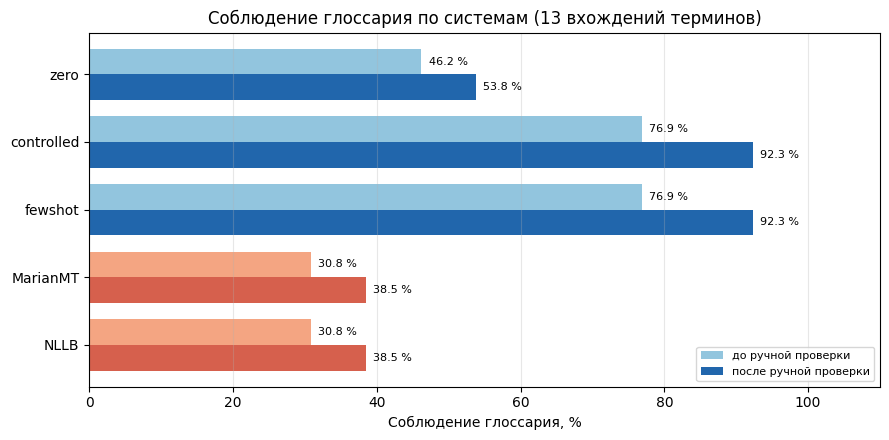

In [ ]:
# 🧩 ЗАДАНИЕ А: диаграмма соблюдения глоссария
import numpy as np
import matplotlib.pyplot as plt

systems_names = compliance_df["system"].tolist()
before = compliance_df["compliance_auto_%"].tolist()
after = compliance_df["compliance_checked_%"].tolist()
nmt_mask = [s in ("MarianMT", "NLLB") for s in systems]

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(systems))
h = 0.38

# «до» — светлые столбцы, «после» — насыщенные; NMT — другим цветом
colors_before = ["#f4a582" if nmt else "#92c5de" for nmt in nmt_mask]
colors_after  = ["#d6604d" if nmt else "#2166ac" for nmt in nmt_mask]

ax.barh(y - h/2, before, height=h, color=colors_before, label="до ручной проверки")
ax.barh(y + h/2, after,  height=h, color=colors_after,  label="после ручной проверки")

for i, (b, a) in enumerate(zip(before, after)):
    ax.text(b + 1, i - h/2, f"{b:.1f} %", va="center", fontsize=8)
    ax.text(a + 1, i + h/2, f"{a:.1f} %", va="center", fontsize=8)

ax.set_yticks(y, systems)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("Соблюдение глоссария, %")
ax.set_title(f"Соблюдение глоссария по системам ({int(compliance_df['occurrences'].iloc[0])} вхождений терминов)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "terminology_compliance.png", dpi=150, bbox_inches="tight")
plt.show()

## Блок 9. Разметка, числа, код, модальность и алфавит

**Зачем.** В учебном тексте часть элементов нельзя переводить или менять. Проверочные случаи строятся из
ваших сегментов: выделение термина `**…**`, список из двух сегментов и фрагмент кода с числом и путём к
файлу. Отдельно проверяется модальность (*must*, *should*, *require*) и **алфавит**: слова, в которых
смешаны латиница и кириллица («датalink»), и непереведённые английские слова. Такие ошибки проходят и
проверку «кириллицы не меньше 50 %», и терминологическую QA, если слова нет в глоссарии.

In [ ]:
# ============================================================================
#  Блок 9. Разметка, числа, код, модальность и смешение алфавитов
# ============================================================================
def markup_cases() -> List[Dict[str, str]]:
    with_terms = [sid for sid in TEST_IDS if relevant_terms(SRC_BY_ID[sid])]
    base = (with_terms + [sid for sid in TEST_IDS if sid not in with_terms])[:3]
    base = (base * 3)[:3]                       # на случай очень маленького корпуса
    sid = base[0]
    terms_here = relevant_terms(SRC_BY_ID[sid])
    term_en, term_ru = terms_here[0] if terms_here else (SRC_BY_ID[sid].split()[1], "—")
    return [
        {"case": "bold", "segment_id": sid,
         "source": re.sub(re.escape(term_en), f"**{term_en}**", SRC_BY_ID[sid], count=1, flags=re.I),
         "expected": f"термин «{term_ru}» выделен **…**"},
        {"case": "list", "segment_id": base[1],
         "source": f"- {SRC_BY_ID[base[1]]}\n- {SRC_BY_ID[base[2]]}",
         "expected": "два пункта списка, маркеры «- » сохранены"},
        {"case": "code", "segment_id": base[0],
         "source": SRC_BY_ID[base[0]] + " Set `MAX_RATE = 200` in `config/params.yaml`.",
         "expected": "фрагменты в `…` не изменены"},
    ]


def markup_report(source: str, translation: str) -> Dict[str, Any]:
    code_src, code_tgt = re.findall(r"`[^`]+`", source), re.findall(r"`[^`]+`", translation)
    nums_src = re.findall(r"\d+(?:[.,]\d+)?", source)
    nums_tgt = re.findall(r"\d+(?:[.,]\d+)?", translation)
    return {"bold_ok": source.count("**") == translation.count("**"),
            "list_ok": len(re.findall(r"^- ", source, re.M)) == len(re.findall(r"^- ", translation, re.M)),
            "code_ok": code_src == code_tgt,
            "numbers_ok": sorted(n.replace(",", ".") for n in nums_src)
                          == sorted(n.replace(",", ".") for n in nums_tgt)}


markup_rows = []
for case in markup_cases():
    record = translate(case["segment_id"], case["source"], "controlled")
    record["mode"] = f"markup_{case['case']}"
    records.append(record)
    markup_rows.append({"case": case["case"], "segment_id": case["segment_id"],
                        "source": case["source"], "translation": record["translation"],
                        **markup_report(case["source"], record["translation"])})
markup_df = pd.DataFrame(markup_rows)
markup_df.to_csv(RESULTS / "markup_checks.csv", index=False, encoding="utf-8-sig")
print("Разметка (режим controlled):")
print(markup_df[["case", "bold_ok", "list_ok", "code_ok", "numbers_ok"]].to_string(index=False))

# --- модальность -----------------------------------------------------------------------
MODAL_EN = r"\b(must|should|can|cannot|may|need to|requires?|required)\b"
MODAL_RU = r"(должн|следует|может|могут|можно|нельзя|необходим|нужно|требу)"
modality = []
for sid in TEST_IDS:
    match = re.search(MODAL_EN, SRC_BY_ID[sid], re.I)
    if match:
        for system, table in systems.items():
            modality.append({"segment_id": sid, "system": system, "modal_en": match.group(0),
                             "preserved": bool(re.search(MODAL_RU, table.get(sid, ""), re.I)),
                             "translation": table.get(sid, "")})
modality_df = pd.DataFrame(modality, columns=["segment_id", "system", "modal_en", "preserved", "translation"])
print(f"\nСегментов с модальностью: {modality_df['segment_id'].nunique()}")
if len(modality_df):
    print(modality_df[["segment_id", "system", "modal_en", "preserved"]].to_string(index=False))


# --- смешение алфавитов и непереведённые слова -------------------------------------------
def script_issues(text: str) -> Tuple[List[str], List[str]]:
    plain = re.sub(r"`[^`]+`", " ", text or "")           # код в обратных кавычках не учитываем
    tokens = re.findall(r"[A-Za-zА-Яа-яЁё]+", plain)
    mixed = [t for t in tokens if re.search(r"[A-Za-z]", t) and re.search(r"[А-Яа-яЁё]", t)]
    latin = [t for t in tokens if re.fullmatch(r"[A-Za-z]+", t)]
    return mixed, latin


script_rows = []
for system, table in systems.items():
    for sid in TEST_IDS:
        mixed, latin = script_issues(table.get(sid, ""))
        if mixed or latin:
            script_rows.append({"segment_id": sid, "system": system, "mixed_words": len(mixed),
                                "latin_words": len(latin), "words": ", ".join(mixed + latin),
                                "translation": table.get(sid, "")})
script_df = pd.DataFrame(script_rows, columns=["segment_id", "system", "mixed_words", "latin_words",
                                               "words", "translation"])
script_summary = (script_df.groupby("system")[["mixed_words", "latin_words"]].sum()
                  .reindex(list(systems), fill_value=0))
print("\nСмешанный алфавит и латиница в переводах (тестовые сегменты):")
print(script_summary.to_string())
if len(script_df):
    print("\nПримеры:")
    print(script_df[["segment_id", "system", "words"]].head(10).to_string(index=False))

Разметка (режим controlled):
case  bold_ok  list_ok  code_ok  numbers_ok
bold     True     True     True        True
list     True     True     True        True
code     True     True     True        True

Сегментов с модальностью: 2
segment_id     system modal_en  preserved
      s006       zero      may       True
      s006 controlled      may       True
      s006    fewshot      may       True
      s006   MarianMT      may       True
      s006       NLLB      may       True
      s007       zero     must       True
      s007 controlled     must       True
      s007    fewshot     must       True
      s007   MarianMT     must       True
      s007       NLLB     must       True

Смешанный алфавит и латиница в переводах (тестовые сегменты):
            mixed_words  latin_words
system                              
zero                  0            2
controlled            0            4
fewshot               0            0
MarianMT              0            0
NLLB               

Разметка, числа, код и модальность сохранены полностью (12 из 12 флагов, 10 из 10 по модальности). Смешанного алфавита нет, а латиница у LLM (2 слова у zero, 4 у controlled) в основном оказывается допустимым глоссированием, которое не ловят ни проверка кириллицы, ни терминологическая QA.

## Блок 10. Targeted repair

**Зачем.** Показать, что нарушение можно исправить **точечно**, не переводя сегмент заново. Для сегментов
с нарушениями отправляется узкая инструкция со списком «английский термин → обязательный эквивалент».

**Откуда берутся случаи.** Сначала из лучших режимов (few-shot, controlled), затем из zero-shot. Если у
LLM нарушений меньше трёх, исправляются переводы MarianMT и NLLB из ЛР № 2: LLM работает как
пост-редактор NMT.

**Двойной контроль.** После исправления заново считается число нарушений, а `unchanged_ratio` — доля
неизменённого текста (сходство строк до и после) — показывает, не переписала ли модель перевод целиком:
около 0,9 — точечная правка, ниже 0,7 — фактически новый перевод.

In [ ]:
# ============================================================================
#  Блок 10. Targeted repair: узкое исправление только найденных нарушений
# ============================================================================
PRIORITY = ["fewshot", "controlled", "zero"] + [s for s in ("MarianMT", "NLLB") if s in systems]
candidates = []
for mode in PRIORITY:
    for sid in TEST_IDS:
        found_violations = term_violations(SRC_BY_ID[sid], systems[mode].get(sid, ""))
        if found_violations:
            candidates.append((mode, sid, found_violations))
print(f"Сегментов с нарушениями: {len(candidates)} (минимум для работы: {N_REPAIR_MIN})")

repair_rows = []
for mode, sid, found_violations in candidates[: max(N_REPAIR_MIN, 5)]:
    before = systems[mode][sid]
    prompt = REPAIR_TEMPLATE.format(
        segment_id=sid, source=SRC_BY_ID[sid], translation=before,
        violations="\n".join(f"- {v['source_term']} → {v['expected']}" for v in found_violations))
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    record = translate(sid, SRC_BY_ID[sid], f"repair_{mode}", messages=messages)
    records.append(record)
    after = record["translation"] or before
    remaining = term_violations(SRC_BY_ID[sid], after)
    repair_rows.append({
        "segment_id": sid, "mode": mode,
        "violations_before": len(found_violations), "violations_after": len(remaining),
        "unchanged_ratio": round(difflib.SequenceMatcher(None, before, after).ratio(), 3),
        "before": before, "after": after,
        "terms": "; ".join(v["source_term"] for v in found_violations)})

repair_df = pd.DataFrame(repair_rows, columns=["segment_id", "mode", "violations_before", "violations_after",
                                               "unchanged_ratio", "before", "after", "terms"])
repair_df.to_csv(RESULTS / "repair_cases.csv", index=False, encoding="utf-8-sig")
if len(repair_df):
    print(f"Нарушений до repair: {repair_df['violations_before'].sum()}, "
          f"после: {repair_df['violations_after'].sum()}; "
          f"средняя доля неизменённого текста: {repair_df['unchanged_ratio'].mean():.2f}\n")
    for row in repair_df.itertuples(index=False):
        print(f"[{row.segment_id} · {row.mode}] ratio={row.unchanged_ratio}\n  до   : {row.before}\n"
              f"  после: {row.after}")
else:
    print("Нарушений нет — repair не потребовался. Отметьте это в отчёте.")
repair_df.drop(columns=["before", "after"])

Сегментов с нарушениями: 29 (минимум для работы: 3)
Нарушений до repair: 5, после: 5; средняя доля неизменённого текста: 0.97

[s002 · fewshot] ratio=0.957
  до   : Цель сейсморазведки заключается в получении информации о породах на основе наблюдаемого времени прихода волны, амплитуды, частоты и формы сигнала.
  после: Цель сейсморазведочных работ заключается в получении информации о породах на основе наблюдаемого времени прихода волны, амплитуды, частоты и формы сигнала.
[s005 · fewshot] ratio=0.99
  до   : Неорганическая теория предполагает, что углерод и водород соединялись под воздействием высокого давления и температуры в глубоких недрах Земли, в результате чего образовывались нефть и газ.
  после: Неорганическая теория предполагает, что углерод и водород соединялись под воздействием высокого **давления** и температуры в глубоких недрах Земли, в результате чего образовывались нефть и газ.
[s011 · fewshot] ratio=0.945
  до   : Производственные скважины бурят для восполнения нефти и

,segment_id,mode,violations_before,violations_after,unchanged_ratio,terms
0,s002,fewshot,1,1,0.957,exploration
1,s005,fewshot,1,1,0.990,pressure
2,s011,fewshot,1,1,0.945,recover
3,s002,controlled,1,1,0.957,exploration
4,s005,controlled,1,1,0.990,pressure


Repair сохранил текст, но не устранил нарушения. В s002 модель заменила синоним на синоним, в s005 выделила слово жирным вместо замены, а в s011 ухудшила перевод; кальки и ошибки вне глоссария вроде «Этапии» в s004 repair не трогает, потому что их не было в списке нарушений.

### 🧩 Задание Б. Эффект точечного исправления

**Цель.** Показать на одном рисунке два результата repair: **исправлены ли термины** и **не переписан ли
перевод целиком**.

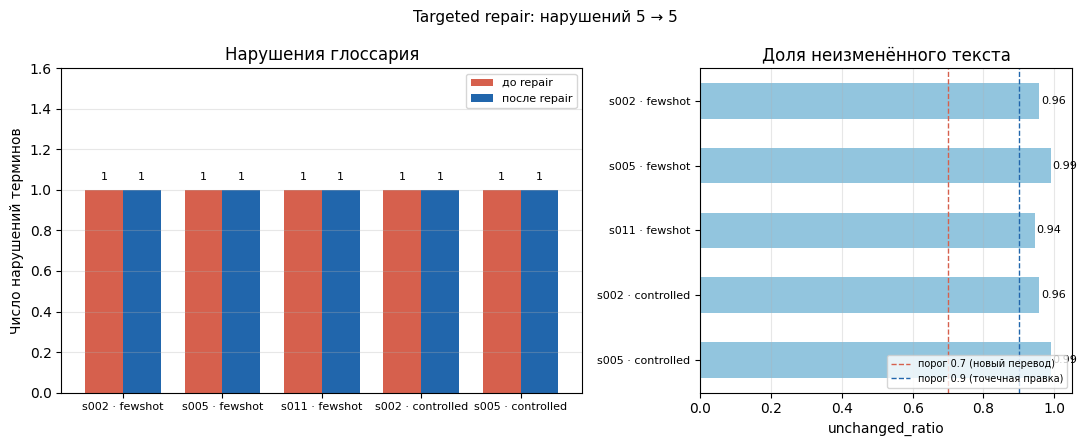

In [ ]:
# 🧩 ЗАДАНИЕ Б: эффект repair
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

labels = [f"{r.segment_id} · {r.mode}" for r in repair_df.itertuples(index=False)]
x = np.arange(len(repair_df))
w = 0.38

# --- левый график: нарушения до/после ---
ax1.bar(x - w/2, repair_df["violations_before"], width=w, label="до repair", color="#d6604d")
ax1.bar(x + w/2, repair_df["violations_after"], width=w, label="после repair", color="#2166ac")
for i, r in enumerate(repair_df.itertuples(index=False)):
    ax1.text(i - w/2, r.violations_before + 0.05, str(r.violations_before), ha="center", fontsize=8)
    ax1.text(i + w/2, r.violations_after + 0.05, str(r.violations_after), ha="center", fontsize=8)
ax1.set_xticks(x, labels, fontsize=8)
ax1.set_ylabel("Число нарушений терминов")
ax1.set_ylim(0, max(repair_df["violations_before"].max(), 1) + 0.6)
ax1.legend(fontsize=8)
ax1.grid(axis="y", alpha=0.3)
ax1.set_title("Нарушения глоссария")

# --- правый график: unchanged_ratio с порогами ---
y = np.arange(len(repair_df))
ax2.barh(y, repair_df["unchanged_ratio"], height=0.55, color="#92c5de")
ax2.axvline(0.7, color="#d6604d", linestyle="--", linewidth=1, label="порог 0.7 (новый перевод)")
ax2.axvline(0.9, color="#2166ac", linestyle="--", linewidth=1, label="порог 0.9 (точечная правка)")
for i, r in enumerate(repair_df.itertuples(index=False)):
    ax2.text(r.unchanged_ratio + 0.005, i, f"{r.unchanged_ratio:.2f}", va="center", fontsize=8)
ax2.set_yticks(y, labels, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(0, 1.05)
ax2.set_xlabel("unchanged_ratio")
ax2.legend(fontsize=7, loc="lower right")
ax2.grid(axis="x", alpha=0.3)
ax2.set_title("Доля неизменённого текста")

total_before = int(repair_df["violations_before"].sum())
total_after = int(repair_df["violations_after"].sum())
fig.suptitle(f"Targeted repair: нарушений {total_before} → {total_after}", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "repair_effect.png", dpi=150, bbox_inches="tight")
plt.show()

## Блок 11. Управление стилем

**Зачем.** Один и тот же сегмент переводится в академическом стиле (A) и в стиле преподавателя,
объясняющего первокурснику (B). Для педагога это ключевая возможность LLM: текст адаптируется под
аудиторию, **а терминология остаётся прежней**.

In [ ]:
# ============================================================================
#  Блок 11. Управление стилем: академический (A) и инструктивный (B)
# ============================================================================
def style_metrics(text: str) -> Dict[str, Any]:
    tokens = re.findall(r"[\wёЁ-]+", text)
    return {"words": len(tokens),
            "you_forms": len(re.findall(r"\b(вы|вам|вас|ваш\w*)\b", text, re.I)),
            "imperatives": len(re.findall(r"\b\w+(?:ите|йте)\b", text, re.I)),
            "passive_or_impersonal": len(re.findall(r"\b\w+(?:ется|ются|ится|ятся)\b", text, re.I))}


style_ids = [sid for sid in TEST_IDS
             if re.search(r"\b(operator|before|check|upload|calibrat)", SRC_BY_ID[sid], re.I)]
style_ids = (style_ids + [sid for sid in TEST_IDS if sid not in style_ids])[:N_STYLE]
style_rows = []
for sid in style_ids:
    row = {"segment_id": sid, "source": SRC_BY_ID[sid]}
    for style in ("A", "B"):
        record = translate(sid, SRC_BY_ID[sid], f"style_{style}", style=style)
        records.append(record)
        row[f"style_{style}"] = record["translation"]
        row.update({f"{k}_{style}": v for k, v in style_metrics(record["translation"]).items()})
        row[f"violations_{style}"] = len(term_violations(SRC_BY_ID[sid], record["translation"]))
    style_rows.append(row)
style_df = pd.DataFrame(style_rows)
style_df.to_csv(RESULTS / "style_comparison.csv", index=False, encoding="utf-8-sig")
for row in style_rows:
    print(f"[{row['segment_id']}] {row['source']}\n  A: {row['style_A']}\n  B: {row['style_B']}\n")
style_df.drop(columns=["source", "style_A", "style_B"])

[s001] Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
  A: Осадочные породы образуются в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  B: Осадочные породы образуются в результате оседания органических и неорганических веществ на дне водных бассейнов и на поверхности континентов.

[s002] Seismic exploration goal is to obtain information on rocks on the basis of observed time of wave arrival, amplitude, frequency and form of signal.
  A: Цель сейсморазведочных работ заключается в получении информации о горных породах на основе наблюдаемого времени прихода волны, амплитуды, частоты и формы сигнала.
  B: Цель сейсморазведки — получить информацию о породах на основе наблюдаемого времени прихода волны, амплитуды, частоты и формы сигнала.

[s003] Rocks saturated with oil or gas, have lower density than the same rocks containing water.
  A: П

,segment_id,words_A,you_forms_A,imperatives_A,passive_or_impersonal_A,violations_A,words_B,you_forms_B,imperatives_B,passive_or_impersonal_B,violations_B
0,s001,17,0,0,1,0,18,0,0,1,0
1,s002,21,0,0,1,1,17,0,0,0,1
2,s003,15,0,0,0,0,15,0,0,0,0


Стиль B не сработал, причина в описательных сегментах, терминология стабильна. Поскольку стиль B не переключился, описание в инструкцию не превратилось и смысл исходника не изменился».

### 🧩 Задание В. Чем различаются стили A и B

**Цель.** Показать, что стиль управляем (или нет), а терминология при смене стиля не страдает.

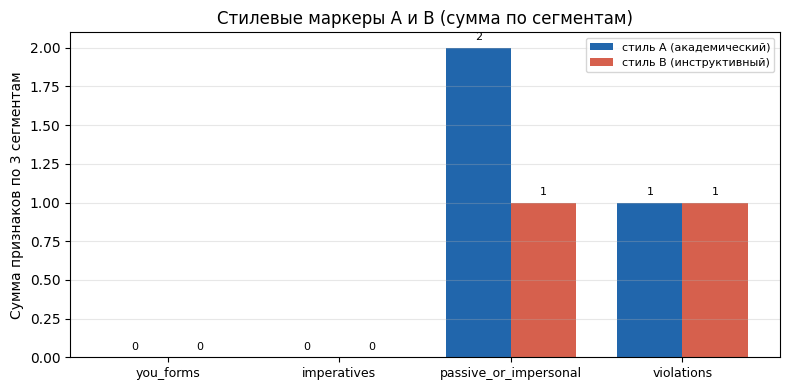

,A,B
you_forms,0,0
imperatives,0,0
passive_or_impersonal,2,1
violations,1,1


In [ ]:
# 🧩 ЗАДАНИЕ В: признаки стиля A и B (8–12 строк)
import numpy as np
import matplotlib.pyplot as plt

markers = ["you_forms", "imperatives", "passive_or_impersonal", "violations"]
style_totals = pd.DataFrame({
    "A": [style_df[f"{m}_A"].sum() for m in markers],
    "B": [style_df[f"{m}_B"].sum() for m in markers],
}, index=markers)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(markers))
w = 0.38
ax.bar(x - w/2, style_totals["A"], width=w, label="стиль A (академический)", color="#2166ac")
ax.bar(x + w/2, style_totals["B"], width=w, label="стиль B (инструктивный)", color="#d6604d")
for i, (a, b) in enumerate(zip(style_totals["A"], style_totals["B"])):
    ax.text(i - w/2, a + 0.05, str(int(a)), ha="center", fontsize=8)
    ax.text(i + w/2, b + 0.05, str(int(b)), ha="center", fontsize=8)
ax.set_xticks(x, markers, fontsize=9)
ax.set_ylabel("Сумма признаков по 3 сегментам")
ax.set_title("Стилевые маркеры A и B (сумма по сегментам)")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "style_markers.png", dpi=150, bbox_inches="tight")
plt.show()
style_totals

# ваш код: таблица style_totals и диаграмма FIGURES / "style_markers.png"

## Блок 12. Сводная таблица и экспертные решения

**Зачем.** Свести эталон ЛР № 1, переводы NMT из ЛР № 2 и три режима LLM в одну таблицу и принять по
сегментам экспертные решения. Типы различий — как в ЛР № 2 (по MQM): **точность**, **терминология**,
**беглость**, **стиль**, **разметка**.

**Ячейка ниже печатает все 12 сегментов** со всеми переводами и пометками: ⚑ — нарушение глоссария,
✳ — смешанный алфавит или латиница. Прочитайте их перед тем, как заполнять `EXPERT`.

In [ ]:
# ============================================================================
#  Блок 12. Сводная таблица переводов
# ============================================================================
comparison = pd.DataFrame({"segment_id": TEST_IDS,
                           "source": [SRC_BY_ID[s] for s in TEST_IDS],
                           "reference": [REF_BY_ID[s] for s in TEST_IDS]})
for system, table in systems.items():
    comparison[system] = [table.get(sid, "") for sid in TEST_IDS]

for row in comparison.to_dict("records"):
    print(f"[{row['segment_id']}] {row['source']}")
    print(f"  {'эталон':<11}: {row['reference']}")
    for system in systems:
        text = row[system]
        flags = ("⚑" if term_violations(row["source"], text) else " ") + \
                ("✳" if any(script_issues(text)) else " ")
        print(f"  {system:<11}{flags}: {text}")
    print()

[s001] Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
  эталон     : Осадочные породы образовались в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности материков.
  zero         : Осадочные породы образуются в результате оседания органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  controlled   : Осадочные породы образуются в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  fewshot      : Осадочные породы образуются в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  MarianMT     : Осадочные породы, образующиеся в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  NLLB         : Осадочные породы, образовавшиеся в результате размещения

### Блок 12.1. Экспертные решения

Для каждого выбранного сегмента укажите, какой перевод предпочтительнее, и **аргументируйте с типом
различия**. Хорошее решение называет конкретное слово и тип ошибки у остальных систем.

In [ ]:
EXPERT: Dict[str, Tuple[str, str]] = {
    "s004": ("controlled",
        "Точность: zero даёт неологизм «Этапия», оставляет wildcats и subsequently непереведёнными, теряет связку; "
        "MarianMT — бессмыслица «бурение диких костей», NLLB — «диких кошек»; "
        "controlled даёт связный текст с «геологоразведочных работ» и «скважин-пробников», хотя wildcats передан описательно."),

    "s006": ("controlled",
        "Терминология: controlled и fewshot передают blowout как «выброс», совпадая с эталоном; "
        "zero — «разрыв скважины», MarianMT — «разрыв нефти и газа», NLLB — «взрыв»; "
        "«взрыв» и «разрыв» искажают смысл (выброс ≠ взрыв)."),

    "s007": ("fewshot",
        "Терминология: fewshot даёт «предохранителем от выброса» — ближе к эталонному «противовыбросовым превентором»; "
        "controlled — описательный неологизм «выбросоуловителем», zero — «предохранителем от выброса» без согласования, "
        "MarianMT — «противоударным устройством», NLLB — «предотвратителем взрыва»; "
        "ни один не дал нормативного термина, но fewshot ближе всех."),

    "s008": ("controlled",
        "Терминология и разметка: controlled передаёт «предотвращатели выброса (blowout preventers)» — "
        "термин по-русски плюс английский оригинал в скобках (глоссирование, допустимо в учебном тексте); "
        "zero — «разрывов скважины» вместо выбросов, MarianMT — «продувки скважин», NLLB — «взрывов скважины»; "
        "fewshot — «предохранительные затворы (БПЗ)» — узуально, но не по глоссарию."),

    "s009": ("controlled",
        "Терминология: controlled даёт «Фонтанное устьевое оборудование (Christmas tree)» — точнее эталона «Фонтанная арматура», "
        "с пояснением английского оригинала; fewshot — «Фонтанное устьевое оборудование» без пояснения, тоже верно; "
        "zero — буквальное «Хвойное дерево», MarianMT — «Рождественская ёлка», NLLB — «Рождественская елка» — "
        "классическая калька на многозначном термине."),

    "s011": ("zero",
        "Точность: zero даёт «для добычи нефти и газа» — смысл передан верно (хотя не по глоссарию); "
        "controlled и fewshot — «для восполнения нефти» — смысловая ошибка: recover здесь «извлекать», "
        "а «восполнять» относится к пластовому давлению; MarianMT — «скважины скапливаются», NLLB — «зачисляются» — "
        "грубые ошибки на spudded; ни один не дал эталонного «для извлечения», но zero ближе всех по смыслу."),

    "s012": ("controlled",
        "Терминология: controlled/fewshot/zero дают «коллоидных суспензий в нефти» — совпадает с эталоном; "
        "MarianMT — «коллоидные подвески в масле», NLLB — «коллоидных суспензий в масле» — "
        "ошибка на oil: asphaltenes существуют в нефти, а не в масле; «подвески» — калька suspensions."),
}

comparison["preferred"] = ""
comparison["comment"] = ""
for sid, (choice, note) in EXPERT.items():
    comparison.loc[comparison["segment_id"] == sid, ["preferred", "comment"]] = [choice, note]
comparison.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
filled = int(((comparison["preferred"] != "") & (comparison["comment"].str.len() > 10)).sum())
print(f"Экспертных решений с аргументом: {filled} (требуется ≥ 5)")

Экспертных решений с аргументом: 7 (требуется ≥ 5)


### 🧩 Задание Г. Сводная таблица систем

**Цель.** Одна таблица, по которой видно, чем отличаются системы: формат, скорость, терминология, алфавит,
близость к эталону.


In [ ]:
# 🧩 ЗАДАНИЕ Г: сводная таблица систем mode_summary
def norm(text: str) -> str:
    return re.sub(r"\W+", " ", (text or "").lower()).strip()

ref_len = sum(len(REF_BY_ID[sid]) for sid in TEST_IDS)
rows = []
for system, table in systems.items():
    is_llm = system in MODES
    r = runs[runs["mode"] == system] if is_llm else pd.DataFrame()
    comp = compliance_df[compliance_df["system"] == system]
    tr_len = sum(len(table.get(sid, "")) for sid in TEST_IDS)
    same = sum(1 for sid in TEST_IDS if norm(table.get(sid, "")) == norm(REF_BY_ID[sid]))
    rows.append({
        "system": system,
        "type": "LLM" if is_llm else "NMT",
        "json_valid_%": round(r["json_valid"].mean() * 100, 1) if len(r) else None,
        "mean_latency_s": round(r["latency_s"].mean(), 2) if len(r) else None,
        "violations_checked": int(comp["violations_checked"].iloc[0]) if len(comp) else None,
        "compliance_checked_%": float(comp["compliance_checked_%"].iloc[0]) if len(comp) else None,
        "mixed_words": int(script_summary.loc[system, "mixed_words"]) if system in script_summary.index else 0,
        "latin_words": int(script_summary.loc[system, "latin_words"]) if system in script_summary.index else 0,
        "length_ratio": round(tr_len / ref_len, 3) if ref_len else None,
        "same_as_reference": same,
    })

mode_summary = pd.DataFrame(rows)
mode_summary.to_csv(RESULTS / "mode_summary.csv", index=False, encoding="utf-8-sig")
mode_summary

,system,type,json_valid_%,mean_latency_s,violations_checked,compliance_checked_%,mixed_words,latin_words,length_ratio,same_as_reference
0,zero,LLM,100.0,7.51,6,53.8,0,2,1.034,0
1,controlled,LLM,100.0,5.40,1,92.3,0,4,1.041,1
2,fewshot,LLM,100.0,4.43,1,92.3,0,0,1.034,1
3,MarianMT,NMT,NaN,NaN,8,38.5,0,0,0.999,0
4,NLLB,NMT,NaN,NaN,8,38.5,0,0,1.013,0


## Чек-лист сдачи

In [ ]:
# ============================================================================
#  Чек-лист сдачи и самопроверка функций
# ============================================================================
def _ok(condition: bool, text: str, consequence: str = "") -> bool:
    print(f"{'✅' if condition else '❌'} {text}" + ("" if condition or not consequence else f"  ({consequence})"))
    return bool(condition)


def _self_tests() -> List[str]:
    failed = []
    tests = {
        "relevant_terms": lambda: set(dict(relevant_terms(
            "The operator uploads a new waypoint to the autopilot.",
            pd.DataFrame({"en": ["waypoint", "autopilot", "airframe"],
                          "ru": ["путевая точка", "автопилот", "планёр"]})))) == {"waypoint", "autopilot"},
        "validate_response": lambda: (validate_response('{"segment_id": "s001", "translation": "Связь.", '
                                                        '"used_terms": [], "warnings": []}', "s001")[0] is not None
                                      and validate_response('{"segment_id": "s002", "translation": "Связь.", '
                                                            '"used_terms": [], "warnings": []}', "s001")[0] is None),
        "term_present": lambda: (term_present("наземная станция управления", "включает наземную станцию управления")
                                 and term_present("угол атаки", "превышение критического угла атаки")
                                 and not term_present("планёр", "стабилизирует воздушное пространство")),
        "markup_report": lambda: all(markup_report("Set `MAX_RATE = 200` in **flight**.",
                                                   "Задайте `MAX_RATE = 200` в **полёте**.").values()),
    }
    for name, test in tests.items():
        try:
            if not test():
                failed.append(name)
        except Exception as error:
            failed.append(f"{name}: {error}")
    return failed


main_runs = runs[runs["mode"].isin(MODES)]
failed_tests = _self_tests()
print("Пайплайн")
_ok(PROVIDER != "mock", f"реальная LLM: {PROVIDER} / {MODEL}", "mock — работа не засчитывается")
_ok(any(r.get("model_version") for r in records), "версия модели записана в трассировку", "−1")
_ok(all((main_runs["mode"] == m).sum() >= N_TEST for m in MODES),
    f"три режима по {N_TEST} одинаковых сегментов", "критерий «три режима»")
_ok(main_runs["json_valid"].all(), f"валидный JSON: {main_runs['json_valid'].mean():.0%} ответов")
_ok(not set(select_fewshot(SRC_BY_ID[TEST_IDS[0]])) & set(TEST_IDS), "few-shot не пересекается с тестом", "−2")
_ok(not failed_tests, "самопроверка функций пайплайна" + (f": {failed_tests}" if failed_tests else ""))

print("\nВаши решения и анализ")
if "VARIANT" in globals():
    _ok(bool(VARIANT) and bool(VARIANT_DOMAIN), "указаны вариант и предметная область (блок 2)")
described = [sid for sid in select_fewshot(SRC_BY_ID[TEST_IDS[0]]) if FEWSHOT_NOTES.get(sid, "").strip()]
_ok(len(described) >= 2, f"примеры few-shot описаны: {len(described)} (блок 3.1)", "снижает оценку анализа")
_ok((terminology_qa["confirmed"] != "").all(),
    f"QA подтверждена: {(terminology_qa['confirmed'] != '').sum()} из {len(terminology_qa)} (блок 8.1)",
    "ручные колонки не заполнены — −2")
_ok(len(repair_df) >= N_REPAIR_MIN, f"случаев repair: {len(repair_df)}", "критерий repair")
_ok(len(style_df) >= N_STYLE, f"стилистических сравнений: {len(style_df)}")
filled = int(((comparison["preferred"] != "") & (comparison["comment"].str.len() > 10)).sum())
_ok(filled >= 5, f"экспертных решений с аргументом: {filled} из 5 (блок 12.1)",
    "критерий «5+ различий»; ручные колонки — −2")
for label, name in (("А", "terminology_compliance.png"), ("Б", "repair_effect.png"), ("В", "style_markers.png")):
    _ok((FIGURES / name).exists(), f"задание {label}: figures/{name}", "критерий «режимы и стили»")
_ok(isinstance(globals().get("mode_summary"), pd.DataFrame) and len(globals()["mode_summary"]) >= 3,
    "задание Г: таблица mode_summary", "критерий «режимы и стили»")

print("\nСекреты")
secret_values = [v for v in (get_secret(n) for n in SECRET_NAMES) if v and len(v) >= 8]
leaks = [p for p in BASE.rglob("*") if p.is_file() and p.suffix in {".md", ".txt", ".json", ".jsonl", ".csv", ".py", ".ipynb"}
         and any(v in p.read_text(encoding="utf-8", errors="ignore") for v in secret_values)]
_ok(not leaks, "значения секретов не попали в файлы работы" + (f": {leaks}" if leaks else ""), "−4 и отзыв ключа")
print("\nНапоминание: перед публикацией в Git проверьте и историю коммитов — в ней не должно быть .env и ключей.")

Пайплайн
✅ реальная LLM: ollama / qwen3.5:9b
✅ версия модели записана в трассировку
✅ три режима по 12 одинаковых сегментов
✅ валидный JSON: 100% ответов
✅ few-shot не пересекается с тестом
✅ самопроверка функций пайплайна

Ваши решения и анализ
✅ указаны вариант и предметная область (блок 2)
✅ примеры few-shot описаны: 2 (блок 3.1)
✅ QA подтверждена: 31 из 31 (блок 8.1)
✅ случаев repair: 5
✅ стилистических сравнений: 3
✅ экспертных решений с аргументом: 7 из 5 (блок 12.1)
✅ задание А: figures/terminology_compliance.png
✅ задание Б: figures/repair_effect.png
✅ задание В: figures/style_markers.png
✅ задание Г: таблица mode_summary

Секреты
✅ значения секретов не попали в файлы работы

Напоминание: перед публикацией в Git проверьте и историю коммитов — в ней не должно быть .env и ключей.


## Блок 13. Отчёт, README, версии промптов и выгрузка

In [ ]:
# ============================================================================
#  Блок 13. Отчёт, README, версии промптов, зависимости и выгрузка
# ============================================================================
from importlib import metadata


def md_table(frame: pd.DataFrame) -> str:
    columns = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for row in frame.itertuples(index=False):
        lines.append("| " + " | ".join("—" if v is None or (isinstance(v, float) and pd.isna(v))
                                       else str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)


def package_version(name: str) -> str:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return ""


prompt_table = "\n".join(f"| `{name}` | `{prompt_hash(text)}` | {len(text)} |"
                         for name, text in PROMPT_REGISTRY.items())
(BASE / "prompt_versions.md").write_text(
    f"# Версии промптов\n\nВерсия набора: **{PROMPT_VERSION}** (v1.1 — уточнён стиль B)\n\n"
    f"| Промпт | sha256 (10 знаков) | Длина |\n|---|---|---:|\n{prompt_table}\n", encoding="utf-8")

packages = ["pydantic", "python-dotenv", "pandas", "matplotlib",
            {"ollama": "ollama", "gigachat": "gigachat", "yandex": "yandex-ai-studio-sdk"}.get(PROVIDER, "")]
(BASE / "requirements.txt").write_text(
    "\n".join(f"{p}=={package_version(p)}" if package_version(p) else p for p in packages if p) + "\n",
    encoding="utf-8")
(BASE / ".env.example").write_text("GIGACHAT_CREDENTIALS=\nGIGACHAT_SCOPE=GIGACHAT_API_PERS\nGIGACHAT_CA_BUNDLE=\n"
                                   "YANDEX_FOLDER_ID=\nYANDEX_API_KEY=\n", encoding="utf-8")
(BASE / ".gitignore").write_text(".env\n.venv/\n__pycache__/\n*.pyc\n*.cer\n*.crt\n", encoding="utf-8")

with open(RESULTS / "results_llm.jsonl", "w", encoding="utf-8") as handle:
    for record in records:
        handle.write(json.dumps(record, ensure_ascii=False) + "\n")

valid_share = runs.groupby("mode")["json_valid"].mean().mul(100).round(1).to_dict()
model_build = ENVIRONMENT.get("model_digest") or next((r["model_version"] for r in records if r.get("model_version")), "—")
expert_rows = comparison.loc[comparison["preferred"] != "", ["segment_id", "preferred", "comment"]]
summary_table = globals().get("mode_summary")
qa_confirmed = int((terminology_qa["confirmed"] != "").sum())
figures_list = "\n".join(f"- `figures/{p.name}`" for p in sorted(FIGURES.glob("*.png"))) or "- рисунков нет"
local_params = (f"- Параметры Ollama: think={OLLAMA_THINK}, num_ctx={OLLAMA_NUM_CTX}, "
                f"presence_penalty={OLLAMA_PRESENCE_PENALTY}; версия: {ENVIRONMENT.get('ollama_version', '—')}; "
                f"GPU: {ENVIRONMENT.get('gpu', '—')}\n") if PROVIDER == "ollama" else ""
auth = ("локальная модель, ключи не нужны" if PROVIDER == "ollama" else
        "ключи читаются из Colab Secrets / `.env`; в репозитории только `.env.example`")

markup_text = ", ".join(
    f"{row['case']}: " + ("сохранена" if all(row[k] for k in ("bold_ok", "list_ok", "code_ok", "numbers_ok"))
                          else "нарушена") for row in markup_rows)
modality_text = (f"{int(modality_df['preserved'].sum())} из {len(modality_df)} переводов сохранили модальность"
                 if len(modality_df) else "модальных сегментов нет")
script_text = ", ".join(f"{name}: {int(v.mixed_words)}/{int(v.latin_words)}" for name, v in script_summary.iterrows())
summary_block = ("Сводная таблица систем (задание Г):\n\n" + md_table(summary_table)
                 if isinstance(summary_table, pd.DataFrame) else "Сводная таблица систем (задание Г) не построена.")
mock_line = "- ⚠ Режим mock: модель не вызывалась, работа к сдаче не принимается" if PROVIDER == "mock" else ""
if len(repair_df):
    repair_text = (f"Случаев: {len(repair_df)}; нарушений до/после: {int(repair_df['violations_before'].sum())} / "
                   f"{int(repair_df['violations_after'].sum())}; средний unchanged_ratio: "
                   f"{repair_df['unchanged_ratio'].mean():.2f}. Подробно — `results/repair_cases.csv`.")
else:
    repair_text = "Нарушений для исправления не было."
expert_text = "\n".join(f"- **{r.segment_id}** → {r.preferred}: {r.comment}" for r in expert_rows.itertuples(index=False))

report = f"""# Отчёт по лабораторной работе 3 (вариант {VARIANT})

**Предметная область (сквозной кейс ЛР № 1–2):** {VARIANT_DOMAIN or DOMAIN_EN}
**Дата прогона:** {ENVIRONMENT['run_date']}

## 1–3. Модель, версия, авторизация
- Провайдер: `{PROVIDER}`, модель: `{MODEL}`, версия/сборка: `{model_build}`
- Параметры: temperature={TEMPERATURE}, seed={SEED}, max_tokens={MAX_TOKENS}
{local_params}- Авторизация: {auth}
{mock_line}

## 4–5. Системный промпт и JSON Schema
Версия промптов {PROMPT_VERSION}; тексты — `prompts/`, хэши — `prompt_versions.md`.
Схема: `prompts/translation_schema.json` (segment_id, translation, used_terms, warnings);
проверка: синтаксис JSON → Pydantic → segment_id, непустой перевод, доля кириллицы ≥ 50 %.

## 6. Режимы zero / controlled / few-shot ({len(TEST_IDS)} сегментов) и сравнение с NMT
Доля валидных JSON-ответов, %: {valid_share}

Соблюдение глоссария ({occurrences} вхождений терминов; ручных решений {qa_confirmed} из {len(terminology_qa)}):

{md_table(compliance_df)}

{summary_block}

Разметка (controlled): {markup_text}.
Модальность: {modality_text}.
Смешанный алфавит / латиница (смешанные/латинские слова): {script_text}.

Рисунки:
{figures_list}

## 7. Анализ ошибок
Экспертных решений: {len(expert_rows)}

{expert_text}

## 8. Terminology repair
{repair_text}

## 9. Стиль A / B
Сегментов: {len(style_df)}; нарушений глоссария A/B: {int(style_df['violations_A'].sum())} / {int(style_df['violations_B'].sum())}; см. `results/style_comparison.csv`.

## 10. Ограничения и вывод
Ограничения: {len(TEST_IDS)} сегментов, одна модель, temperature={TEMPERATURE}; терминологическая QA — эвристика с ручным подтверждением.

Вывод: см. блок 14 ноутбука.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")

readme = f"""# ЛР № 3. Контекстный перевод и локализация с помощью LLM (вариант {VARIANT})

Управляемый LLM-пайплайн перевода: системная инструкция, термины сегмента из TBX, примеры few-shot из TMX,
JSON Schema + Pydantic, терминологическая QA, targeted repair, сравнение стилей и сравнение с NMT (ЛР № 2).

## Как воспроизвести
1. Открыть `LAB_03.ipynb` в Google Colab, среда — GPU T4.
2. Положить `variant_<N>.tmx`, `variant_<N>.tbx` и `lab02_results.zip` в `lab03/input/`.
3. Выполнить все ячейки. Модель: `{MODEL}` (`{PROVIDER}`), сборка `{model_build}`, temperature {TEMPERATURE}, seed {SEED}.
4. Для облачных моделей задать секреты по образцу `.env.example` (Colab Secrets или `.env`).

## Структура
- `prompts/` — промпты (версия {PROMPT_VERSION}, хэши в `prompt_versions.md`) и JSON Schema
- `results/` — трассировка `results_llm.jsonl`, `terminology_qa.csv`, `markup_checks.csv`, `repair_cases.csv`,
  `style_comparison.csv`, `comparison.csv`, `mode_summary.csv`
- `figures/` — рисунки анализа
- `report.md` — отчёт; `requirements.txt` — зависимости
"""
(BASE / "README.md").write_text(readme, encoding="utf-8")

archive = shutil.make_archive(str(BASE.parent / "lab03_results"), "zip", root_dir=BASE.parent, base_dir=BASE.name)
print("Созданные файлы (без input/ и data/):")
for path in sorted(BASE.rglob("*")):
    relative = path.relative_to(BASE)
    if path.is_file() and relative.parts[0] not in {"input", "data"}:
        print(f"  {str(relative):<40} {path.stat().st_size:>8} байт")
print("Архив:", archive)
if DRIVE_COURSE_DIR.is_dir():
    (DRIVE_COURSE_DIR / "lab03").mkdir(exist_ok=True)
    shutil.copy2(archive, DRIVE_COURSE_DIR / "lab03" / "lab03_results.zip")
    print("Копия на Drive:", DRIVE_COURSE_DIR / "lab03" / "lab03_results.zip")
try:
    from google.colab import files
    files.download(archive)
except Exception:
    pass

Созданные файлы (без input/ и data/):
  .env.example                                  109 байт
  .gitignore                                     43 байт
  README.md                                    1371 байт
  figures/repair_effect.png                   88454 байт
  figures/style_markers.png                   49406 байт
  figures/terminology_compliance.png          58234 байт
  prompt_versions.md                            384 байт
  prompts/fewshot.json                         1291 байт
  prompts/prompt_repair.txt                     787 байт
  prompts/prompt_system.txt                    1631 байт
  prompts/repair.txt                            787 байт
  prompts/system_controlled.txt                1631 байт
  prompts/system_style_A.txt                   1705 байт
  prompts/system_style_B.txt                   1982 байт
  prompts/system_zero.txt                       178 байт
  prompts/translation_schema.json               740 байт
  report.md                                    766

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Блок 14. Выводы

1. Передача глоссария в промпте заметно повышает точность терминов. В режиме zero-shot соблюдение составило 53.8 %, а в controlled и few-shot выросло до 92.3 %. MarianMT и NLLB остались на уровне 38.5 %, и разрыв между LLM с глоссарием и NMT достиг 53.8 п.п. При этом zero-shot оказался ближе к NMT, чем к controlled. Значит, без явной передачи терминов LLM не даёт терминологического выигрыша, и эффект создаёт именно управление глоссарием, а не сама модель.

2. Формат ответа модель соблюдает стабильно: все 36 ответов оказались валидным JSON. Но схема проверяет только структуру, а не смысл. Из 31 срабатывания автоматической проверки 7 оказались ложными, а латиница в переводах (2 слова у zero и 4 у controlled) прошла мимо всех автоматических проверок. Такие случаи различает только человек.

3. Разметку, числа, код и модальность модель сохранила. Все 12 флагов проверки оказались True. Модальность передана в 10 из 10 случаев. Ограничение в том, что модальных сегментов всего два, поэтому вывод о модальности пока предварительный.

4. Точечное исправление (repair) сохранило текст, но не устранило нарушения. Доля неизменённого текста составила 0.945–0.99, то есть перевод не переписывался заново. Однако число нарушений осталось прежним: 5 до и 5 после. Модель заменила «сейсморазведку» на «сейсморазведочные работы», но не на требуемые глоссарием «геологоразведочные работы». В другом случае она просто выделила слово жирным вместо замены, а в s011 ухудшила перевод, заменив «восполнение» на «извлечение». Причина в том, что модель воспринимает repair как общую инструкцию „исправь“, а не как точную замену по списку, поэтому подставляет ближайший синоним вместо глоссарного эквивалента

5. Управление стилем на этом материале не сработало. Обращений на «вы» и побудительных форм не появилось ни в стиле A, ни в стиле B, и разница между ними свелась только к числу безличных конструкций (2 против 1). Причина в том, что все три сегмента описательные, в них нет действий оператора, которые можно было бы переформулировать в шаги читателя. Терминология при этом осталась стабильной: число нарушений в стилях A и B совпало.

6. Сводная таблица подтверждает общую картину. LLM с глоссарием даёт 92.3 % соблюдения против 38.5 % у NMT, валидный JSON составляет 100 %, средняя задержка 4.4–7.5 с на сегмент. Длина переводов LLM на 3–4 % больше эталона, что объясняется разворачиванием составных терминов, а не добавлением фактов. У NMT этот показатель близок к 1.0. Режим few-shot полностью убрал латиницу (0 слов), включая допустимое глоссирование вроде «Фонтанное устьевое оборудование (Christmas tree)», что для учебного текста неоднозначно.

7. Главный вывод работы состоит в том, что LLM отличается от NMT не качеством вообще, а управляемостью. Промпт с глоссарием даёт измеримый прирост (53.8 → 92.3 %), но инструкция не является гарантией. Repair не исправляет термины автоматически, стиль не переключается на описательном материале, а модель не сообщает о своих ошибках (warnings = 0 при подтверждённых нарушениях). Поэтому решение о принятии перевода остаётся за человеком.

8. Ограничения эксперимента связаны с малым объёмом материала. Проверка терминов основана на грубом стемминге и даёт 22.6 % ложных срабатываний. Модальных сегментов всего два, стилевых три, примеров few-shot два, а сравнение с NMT ограничено одним прогоном ЛР № 2. Для устойчивых выводов нужен корпус от 50 сегментов и несколько прогонов с разными seed.